## **1. Tải lại dataframe từ các lab trước**

In [ ]:
import pandas as pd
import pickle
import numpy as np
import matplotlib.pyplot as plt

with open('df_copy.pkl', 'rb') as f:
    df_signal = pickle.load(f)

for ticker in df_signal.keys():
    df_signal[ticker]['Closelog'] = np.log(df_signal[ticker]['Close'])

# In thử kiểm tra
print(df_signal['AAPL'].tail())

                  Open        High         Low       Close   Adj Close  \
Date                                                                     
2025-09-24  255.220001  255.740005  251.039993  252.309998  252.309998   
2025-09-25  253.210007  257.170013  251.710007  256.869995  256.869995   
2025-09-26  254.100006  257.600006  253.779999  255.460007  255.460007   
2025-09-29  254.559998  255.000000  253.009995  254.429993  254.429993   
2025-09-30  254.860001  255.919998  253.110001  254.630005  254.630005   

              Volume      SMA_20      SMA_50    STD_20     STD_50  \
Date                                                                
2025-09-24  42303700  238.300500  226.521144  8.181692  13.472069   
2025-09-25  55202100  239.619499  227.460109  8.946886  13.920156   
2025-09-26  46076300  240.764500  228.373670  9.447231  14.231692   
2025-09-29  40127700  241.878999  229.243458  9.687960  14.471440   
2025-09-30  37704300  243.124500  230.091276  9.643641  14.694921  

In [ ]:
df_signal_copy = df_signal.copy()

## **2. Pairs Trading**

Ta triển khai một chiến lược Pairs Trading truyền thống bằng cách sử dụng **Khoảng cách Euclidean** để chọn cặp, sau đó sử dụng các kiểm định Đồng tích hợp để xác nhận tính phù hợp của cặp.

Ta cần tìm kiếm và lựa chọn các cặp cổ phiếu có hành vi giá tương đồng và thể hiện tính chất quay về trung bình mạnh mẽ bằng cách tính **Euclidean Distance** - đo lường sự tương đồng về hình dạng giữa hai chuỗi lợi nhuận tích lũy.

In [ ]:
import pandas as pd
import numpy as np
import pickle

if 'Summary' in df_signal:
    del df_signal['Summary']
#Xây dựng DataFrame 'prices' chuẩn (Mã cổ phiếu là cột)
prices_list = []
for ticker, df in df_signal.items():
    # Lấy cột 'Close' và đổi tên cột thành Mã cổ phiếu
    price_series = df['Close'].rename(ticker)
    prices_list.append(price_series)

# Kết hợp tất cả Series giá vào một DataFrame duy nhất
prices = pd.concat(prices_list, axis=1)

# Kiểm tra kết quả
print(prices.head())

                 META      F          GS         UNH        NVS  MRNA  \
Date                                                                    
2015-01-02  78.449997  15.36  194.410004  100.779999  82.661293   NaN   
2015-01-05  77.190002  14.76  188.339996   99.120003  82.840500   NaN   
2015-01-06  76.150002  14.62  184.529999   98.919998  82.141579   NaN   
2015-01-07  76.150002  15.04  187.279999   99.930000  82.500000   NaN   
2015-01-08  78.180000  15.42  190.270004  104.699997  85.367386   NaN   

                   BP        CRM  LCID        MCD  ...  VFS         JNJ  \
Date                                               ...                    
2015-01-02  38.119999  59.240002   NaN  93.260002  ...  NaN  104.519997   
2015-01-05  36.099998  58.169998   NaN  92.230003  ...  NaN  103.790001   
2015-01-06  35.830002  57.200001   NaN  92.400002  ...  NaN  103.279999   
2015-01-07  35.919998  56.930000   NaN  94.010002  ...  NaN  105.559998   
2015-01-08  36.730000  58.590000   NaN

Từ đây, ta xây dựng được một dataframe với hàng là **date** và cột là **tên mã** trong đó giá trị là giá đóng cửa.

Sau đó, ta tính toán Lợi nhuận Tích lũy (Cumulative Returns) dựa trên chuỗi giá đóng cửa (được lưu trong biến prices).

Lưu ý rằng, lợi nhuận tích lũy cho biết nếu bạn đầu tư 1 đơn vị tiền tệ (ví dụ: 1 đô la hoặc 1 VNĐ) vào ngày đầu tiên, thì giá trị của khoản đầu tư đó sẽ là bao nhiêu vào bất kỳ ngày nào sau đó, giả sử tất cả lợi nhuận đều được tái đầu tư.

In [ ]:
# 1. Tính lợi nhuận đơn giản: (Price_t - Price_{t-1}) / Price_{t-1}
returns = prices.pct_change()
returns.fillna(0, inplace=True)
# 2. Tính lợi nhuận tích lũy (Giá trị của $1): (1 + returns).cumprod()
cumret = (1 + returns).cumprod()

# Loại bỏ hàng NaN đầu tiên
print(cumret.head())

                META         F        GS       UNH       NVS  MRNA        BP  \
Date                                                                           
2015-01-02  1.000000  1.000000  1.000000  1.000000  1.000000   1.0  1.000000   
2015-01-05  0.983939  0.960938  0.968777  0.983529  1.002168   1.0  0.947009   
2015-01-06  0.970682  0.951823  0.949180  0.981544  0.993713   1.0  0.939927   
2015-01-07  0.970682  0.979167  0.963325  0.991566  0.998049   1.0  0.942287   
2015-01-08  0.996558  1.003906  0.978705  1.038897  1.032737   1.0  0.963536   

                 CRM  LCID       MCD  ...  VFS       JNJ       DHI  PYPL  \
Date                                  ...                                  
2015-01-02  1.000000   1.0  1.000000  ...  1.0  1.000000  1.000000   1.0   
2015-01-05  0.981938   1.0  0.988956  ...  1.0  0.993016  0.979167   1.0   
2015-01-06  0.965564   1.0  0.990778  ...  1.0  0.988136  0.965946   1.0   
2015-01-07  0.961006   1.0  1.008042  ...  1.0  1.009950  1

### **2.1. Functions to calculate different metrics (chọn cặp mã tradeable)**

In [ ]:
def calculate_distances(cumret):
    '''
    Tính khoảng cách Euclidean cho mỗi cặp cổ phiếu trong khung dữ liệu
    Trả về sorted_distances theo thứ tự tăng dần
    '''
    distances = {} # dictionary with distance for each pair

    # calculate distances
    for s1 in cumret.columns:
        for s2 in cumret.columns:
            if s1!=s2 and (f'{s1}-{s2}' not in distances.keys()) and (f'{s2}-{s1}' not in distances.keys()):
                dist = np.sqrt(np.sum((cumret[s1] - cumret[s2])**2)) # Euclidean distance
                distances[f'{s1}-{s2}'] = dist

    # sort dictionary
    sorted_distances = {k:v for k,v in sorted(distances.items(), key = lambda item: item[1])}

    return sorted_distances

def parse_pair(pair):
    '''
    parse pair string S1-S2
    return tickers S1, S2
    '''
    dp = pair.find('-')
    s1 = pair[:dp]
    s2 = pair[dp+1:]

    return s1,s2


def calculate_halflife(spread):
    '''
    tính toán Thời gian bán hủy (Half-life) của tính chất quay về trung bình (mean reversion) của chuỗi chênh lệch (spread).
    '''
    from statsmodels.regression.linear_model import OLS
    from statsmodels.tools.tools import add_constant

    ylag = spread.shift()
    deltay = spread - ylag
    ylag.dropna(inplace=True)
    deltay.dropna(inplace=True)

    res = OLS(deltay, add_constant(ylag)).fit()
    halflife = -np.log(2)/res.params[0]

    return halflife


def plot_pairs(sorted_distances, cumret_train, cumret_test, N=5):
    '''
    Biểu đồ lợi nhuận tích lũy của chênh lệch cho mỗi cặp N có khoảng cách Euclid nhỏ nhất
    '''
    pairs = [k for k,v in sorted_distances.items()][:N]

    for pair in pairs:
        s1,s2 = parse_pair(pair)
        spread_train = cumret_train[s1] - cumret_train[s2]
        spread_test = cumret_test[s1] - cumret_test[s2]
        spread_mean = spread_train.mean() # historical mean
        spread_std = spread_train.std() # historical standard deviation

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18,4))
        fig.suptitle(f'Spread of {pair} pair', fontsize=16)
        ax1.plot(spread_train, label='spread')
        ax1.set_title('Formation period')
        ax1.axhline(y=spread_mean, color='g', linestyle='dotted', label='mean')
        ax1.axhline(y=spread_mean+2*spread_std, color='r', linestyle='dotted', label='2-SD band')
        ax1.axhline(y=spread_mean-2*spread_std, color='r', linestyle='dotted')
        ax1.legend()
        ax2.plot(spread_test, label='spread')
        ax2.set_title('Trading period')
        ax2.axhline(y=spread_mean, color='g', linestyle='dotted', label='mean')
        ax2.axhline(y=spread_mean+2*spread_std, color='r', linestyle='dotted', label='2-SD band')
        ax2.axhline(y=spread_mean-2*spread_std, color='r', linestyle='dotted')
        ax2.legend()

### **2.2. Train_Data/Test_Data**

In [ ]:
cumret_base = cumret.loc['2015-01-01':'2025-10-01'] # Lấy đúng phạm vi thời gian 18 tháng

# Không cần chuẩn hóa lại (chia cho iloc[0]) vì cumret đã được chuẩn hóa
train_data = cumret_base.loc['2015-01-01':'2023-01-1'] # Formation period (12 tháng)
test_data = cumret_base.loc['2023-01-02':'2025-10-01']   # Trading period (6 tháng)

print("Kích thước dữ liệu huấn luyện:", train_data.shape)
print("Kích thước dữ liệu kiểm tra:", test_data.shape)

Kích thước dữ liệu huấn luyện: (2014, 66)
Kích thước dữ liệu kiểm tra: (688, 66)


### **2.3. Trading period**

In [ ]:
# Tính khoảng cách Euclidean
sorted_distances = calculate_distances(train_data)

# In 10 cặp hàng đầu
print("10 cặp có khoảng cách nhỏ nhất:")
[[k,v] for k,v in sorted_distances.items()][:10]

10 cặp có khoảng cách nhỏ nhất:


[['PEP-JNJ', np.float64(4.734538987189463)],
 ['NVS-VFS', np.float64(4.840037248621769)],
 ['BP-SHEL', np.float64(5.333055768265504)],
 ['WMT-PG', np.float64(5.395999256332479)],
 ['XOM-SHEL', np.float64(5.710615223346982)],
 ['SNOW-RIVN', np.float64(6.529688264973452)],
 ['SNOW-VFS', np.float64(6.774128555893794)],
 ['GS-ORCL', np.float64(6.830188616880826)],
 ['PFE-JNJ', np.float64(6.920478813817346)],
 ['KO-PFE', np.float64(7.062144630921608)]]

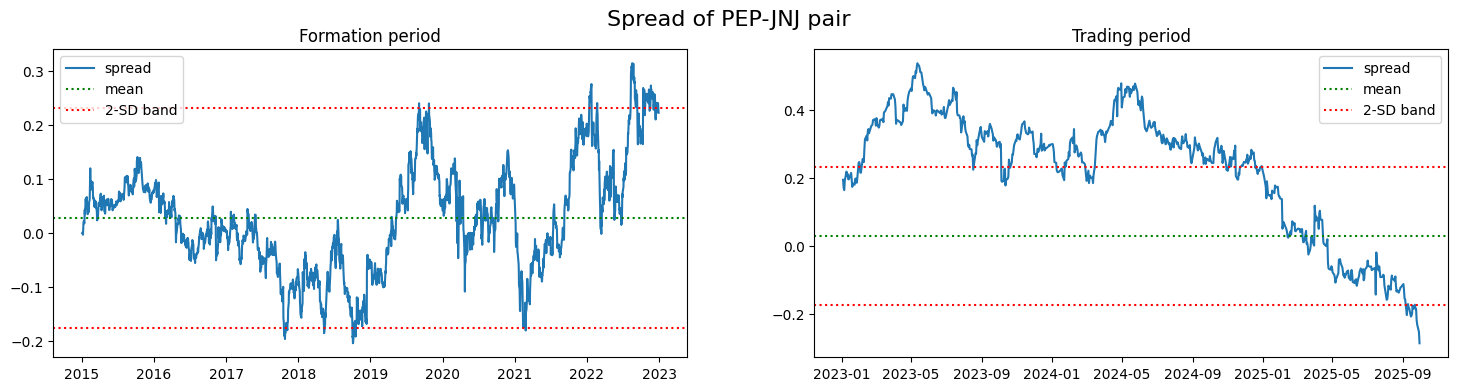

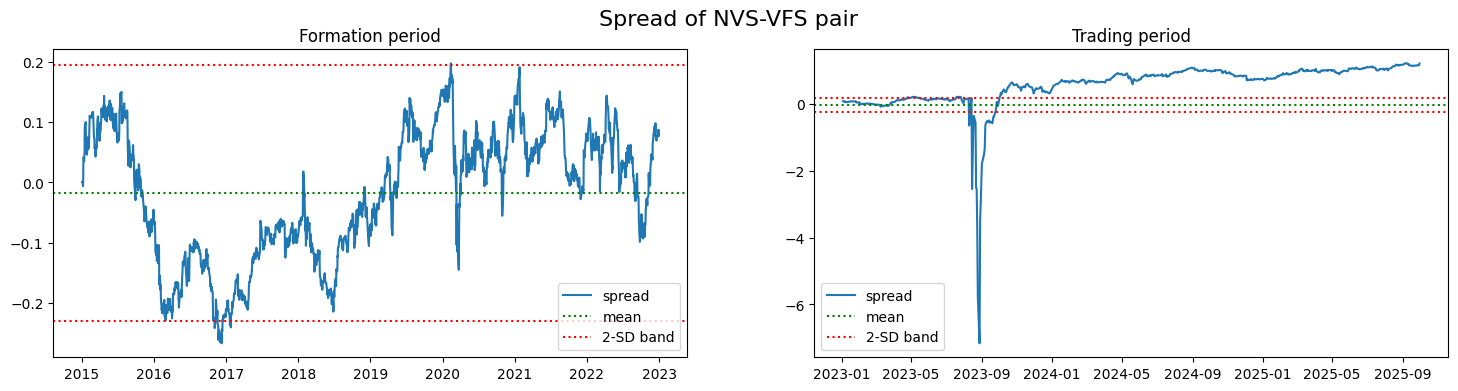

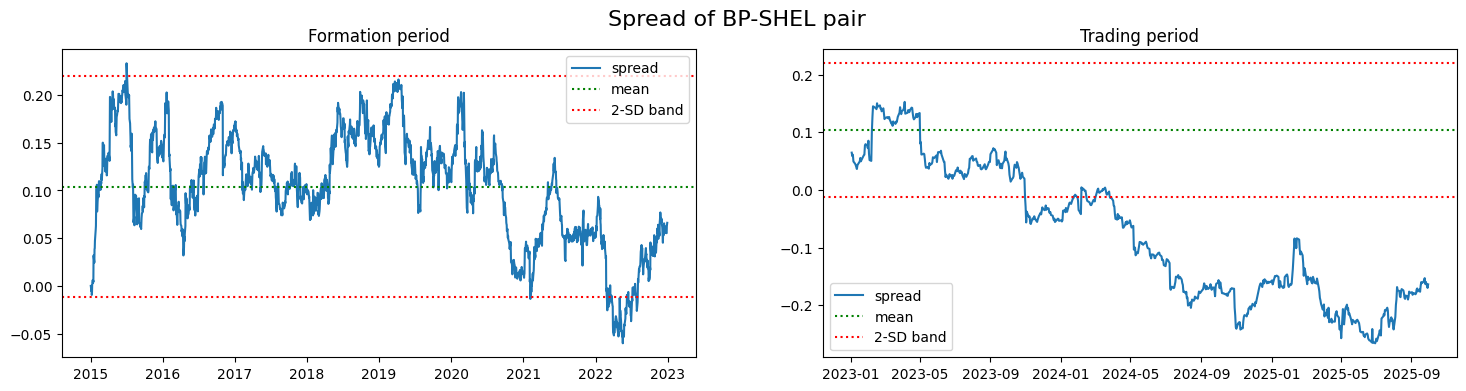

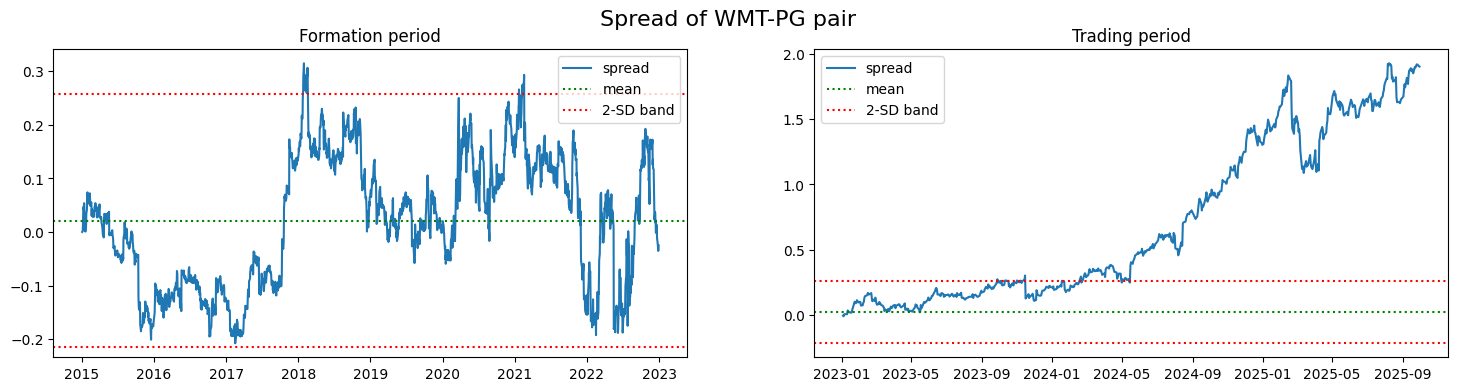

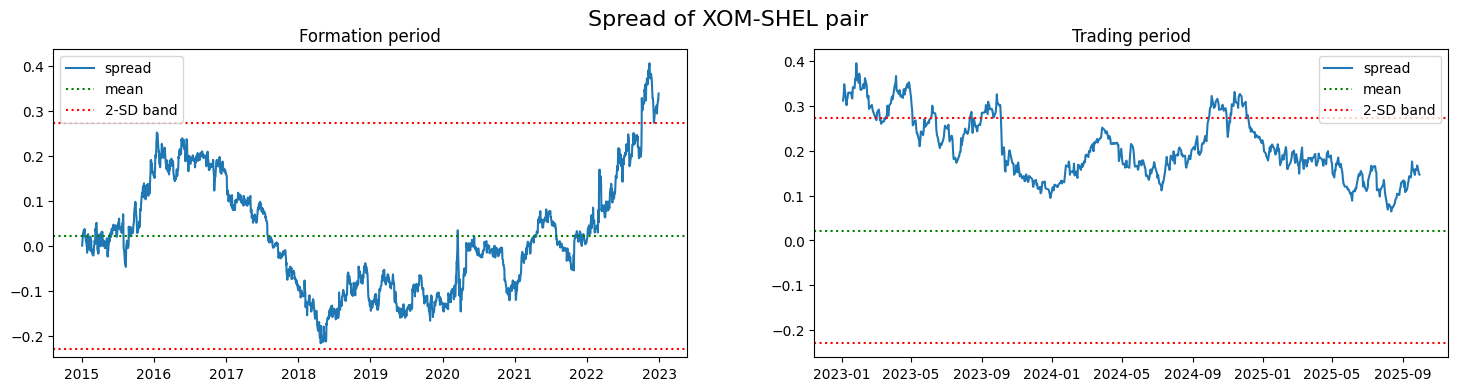

In [ ]:
plot_pairs(sorted_distances, train_data, test_data)

In 5 biểu đồ hiển thị **Hành vi chênh lệch(Spread)** của 5 cặp mã cổ phiếu có khoảng cách ngắn nhất.

(*) Phân tích đồ thị chệnh lệch của PEP-JNJ

Ở biểu đồ formation period, mục đích chính dùng để xách định tính chất của chênh lệch và thiết lập các ngưỡng giao dịch( mean, $\pm2SD$)

- Đường Spread: chuỗi lợi nhuận tích lũy của PEP trừ đi JNJ, qua đó biểu thị chênh lệch giữa 2 tài sản theo thời gian

- Đường trung bình, là mục tiêu mà Spread được kỳ vọng sẽ quay về.

- Băng $\pm2SD$: Phạm vi cách *đường Mean* $\pm2SD$, thiết lập các ngưỡng giao dịch. Ta mua Spread khi nó **dưới -2SD** và bán Spread khi nó **vượt quá +2SD**.

Qua đó trong giai đoạn 2015-2022, Spread thường xuyên quay về đường Mean, xác nhận tính chất **Mean-Reversion**. Spread chạm hoặc vượt băng $\pm2SD$ một vài lần, tạo ra các điểm vào tiền năng.

Ở biểu đồ Trading Period, là giao đoạn dùng để kiểm tra hiệu quả của các ngưỡng Mean và $\pm2SD$ đã được xác định ở giai đoạn hình thành. Nhận thấy rằng, trong khoảng nửa đầu năm 2023, Spread vẫn năm trong băng giao dịch cho thấy tính chất Mean-Reversion vẫn hoạt động ở mức độ chấp nhận được. Tuy nhiên, Spread bắt đầu giảm mạnh vào cuối năm 2024 và rơi xuống băng -2SD , tiếp tục giảm sâu

$\to$ Tính chất Mean-Reversion bị phá vỡ cho thấy một rủi ro lớn

Tổng kết lại, ta có:

- Cặp PEP-JNJ là mọt ứng viên tiềm năng vì quay về trung bình trong quá khứ

- Hành vi củA Spread trong giai đoạn Trading cho thấy cặp này không ổn định trong thời gian dài. Nghĩa là, nếu ta **Short Spread**(bán PEP,mua JNJ) khi Spread chạm mức cao vào giữa năm 2024, ta đã kiếm được lợi nhuận khi nó giảm xuống. Nhưng nếu ta **Long Spread** khi nó xuống dưới -2SD vào cuối năm 2025, ta sẽ bị thua lỗ nặng nề.

Điều này cho thấy cặp **PEP-JNJ** không duy trình tính chất đồng tích hợp và Mean-Reversion của nó trong giai đoạn kiểm tra ngoài mẫu, làn tăng rủi ro khi gioa dịch dựa trên các ngưỡng lịch sử này.

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

def perform_engle_granger_test(s1, s2, cumret):
    """
    Thực hiện Kiểm định Đồng tích hợp Engle-Granger (Dựa trên ADF Test).

    Args:
        s1 (str): Mã cổ phiếu thứ nhất (Ví dụ: 'BXMT').
        s2 (str): Mã cổ phiếu thứ hai (Ví dụ: 'PMT').
        cumret (pd.DataFrame): DataFrame chứa Lợi nhuận Tích lũy đã chuẩn hóa.

    Returns:
        dict: Trả về một từ điển chứa p-value của ADF test và Hedge Ratio (beta).
    """

    # --- BƯỚC 1: Chạy Hồi quy Tuyến tính (OLS) để tìm Hedge Ratio (beta) ---

    # Thiết lập mô hình: P_B = beta * P_A + epsilon
    # Đặt P_B (s2) là biến phụ thuộc (y)
    Y = cumret[s2]
    # Đặt P_A (s1) là biến độc lập (x). sm.add_constant được dùng để thêm hằng số (alpha)
    X = sm.add_constant(cumret[s1])

    # Chạy mô hình Hồi quy Tuyến tính (Ordinary Least Squares - OLS)
    results = sm.OLS(Y, X).fit()

    # Hedge Ratio (beta) là hệ số góc của biến s1 (nằm ở vị trí index 1 trong params)
    beta = results.params[1]

    # --- BƯỚC 2: Tính phần dư (Spread) và chạy kiểm định ADF ---

    # Tính Spread: epsilon_t = P_B - beta * P_A - alpha
    # Phần dư (residuals) chính là chuỗi Spread (chênh lệch)
    spread = results.resid

    # Chạy kiểm định ADF trên chuỗi Spread
    # adfuller trả về một tuple (test_statistic, p_value, ...)
    adf_result = adfuller(spread)

    adf_p_value = adf_result[1]

    # --- Đánh giá ---
    is_cointegrated = adf_p_value <= 0.05

    return {
        'Hedge_Ratio_beta': beta,
        'ADF_p_value': adf_p_value,
        'Is_Cointegrated': is_cointegrated,
        'Spread': spread # Trả về spread để tính toán các metrics khác sau này
    }


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

# GIẢ ĐỊNH: Các biến 'cumret' (DataFrame lợi nhuận tích lũy)
# và 'sorted_distances' (Từ điển các cặp và khoảng cách) đã tồn tại.
# Các hàm 'parse_pair' và 'perform_engle_granger_test' đã được định nghĩa.

results_list = []

# Lặp qua tất cả các cặp trong sorted_distances
for pair, distance in sorted_distances.items():
    s1, s2 = parse_pair(pair)

    # Thực hiện kiểm định đồng tích hợp
    metrics = perform_engle_granger_test(s1, s2, cumret)

    # Thu thập dữ liệu
    pair_result = {
        'Stock 1': s1,
        'Stock 2': s2,
        'Euclidean distance': distance,
        'Hedge_Ratio': metrics['Hedge_Ratio_beta'],
        'ADF_p_value': metrics['ADF_p_value'],
        'Is_Cointegrated': metrics['Is_Cointegrated']
    }
    results_list.append(pair_result)

# Chuyển đổi sang DataFrame
df_results = pd.DataFrame(results_list)

# Lọc DataFrame: chỉ giữ lại các cặp có p-value <= 0.05
df_tradeable = df_results[df_results['ADF_p_value'] <= 0.05]

In [ ]:
print("Các cặp trade được (p <= 0.05):")
print(df_tradeable)

Các cặp trade được (p <= 0.05):
     Stock 1 Stock 2  Euclidean distance  Hedge_Ratio   ADF_p_value  \
1        NVS     VFS            4.840037    -0.842150  3.102685e-07   
6       SNOW     VFS            6.774129     0.433077  1.615822e-05   
10     CMCSA     DIS            7.084824     0.788252  4.719792e-02   
12        PG      KO            7.678838     0.558635  2.049398e-02   
22       CVX     COP            8.546995     1.538020  3.235581e-02   
...      ...     ...                 ...          ...           ...   
2044     AMD     VFS          918.309525    -0.006515  2.123641e-06   
2067    NVDA      GM          936.162967     0.001478  4.795076e-02   
2072    NVDA     VFS          944.360673    -0.002283  4.920406e-10   
2079    NVDA     WBD          952.552968    -0.001977  1.737260e-02   
2134    SHOP     VFS         1578.537548    -0.003473  1.227457e-05   

      Is_Cointegrated  
1                True  
6                True  
10               True  
12               Tr

In [ ]:
df_tradeable.sort_values(by = "Hedge_Ratio")

,Stock 1,Stock 2,Euclidean distance,Hedge_Ratio,ADF_p_value,Is_Cointegrated
223,SNOW,ELF,17.484339,-5.800895,0.031407,True
1310,COTY,NEE,74.249727,-1.797988,0.006040,True
1279,COTY,PLD,70.524950,-1.641344,0.025515,True
256,SNOW,COP,18.494451,-1.517913,0.033392,True
258,KO,RIVN,18.630874,-1.498876,0.044014,True
...,...,...,...,...,...,...
2018,ABBV,AMD,895.735676,26.074529,0.029513,True
2003,LRLCY,AMD,881.295948,29.523728,0.023584,True
1944,NVS,TSLA,402.163808,33.356876,0.049325,True
2029,PG,AMD,903.370567,52.433405,0.002025,True


Sau khi sắp xếp **df_tradeable** theo *Hedge_Ratio* nhận thấy tồn tại những giá trị cực đoan. Các Hedge_Ratio quá lớn (ví dụ: > 30 hoặc < -30) có thể dẫn đến việc định cỡ vị thế mất cân đối hoặc không thực tế (yêu cầu khối lượng cổ phiếu quá lớn cho một mã), nên ta sẽ loại bỏ chúng ra khỏi dataframes

In [ ]:
import pandas as pd

# Giả định: df_tradeable đã được load và chứa dữ liệu như hình ảnh.

# --- Xác định Ngưỡng Lọc ---
# Đặt ngưỡng tối đa và tối thiểu cho Hedge_Ratio
HEDGE_RATIO_MAX = 30
HEDGE_RATIO_MIN = -30

# --- Thực hiện Lọc ---
# Tạo một DataFrame mới (hoặc ghi đè) chỉ chứa các hàng
# mà Hedge_Ratio nằm trong khoảng [HEDGE_RATIO_MIN, HEDGE_RATIO_MAX]
df_filtered = df_tradeable[
    (df_tradeable['Hedge_Ratio'] <= HEDGE_RATIO_MAX) &
    (df_tradeable['Hedge_Ratio'] >= HEDGE_RATIO_MIN)
]

# --- In kết quả để kiểm tra ---
# In ra số lượng hàng trước và sau khi lọc
print(f"Số lượng cặp trước khi lọc: {len(df_tradeable)} rows")
print(f"Số lượng cặp sau khi lọc: {len(df_filtered)} rows")

# Sắp xếp và hiển thị 5 hàng đầu tiên của DataFrame đã lọc
print("\nDataFrame đã lọc (df_filtered) sau khi loại bỏ Hedge_Ratio cực đoan:")
df_filtered.sort_values(by="Hedge_Ratio")

Số lượng cặp trước khi lọc: 303 rows
Số lượng cặp sau khi lọc: 300 rows

DataFrame đã lọc (df_filtered) sau khi loại bỏ Hedge_Ratio cực đoan:


,Stock 1,Stock 2,Euclidean distance,Hedge_Ratio,ADF_p_value,Is_Cointegrated
223,SNOW,ELF,17.484339,-5.800895,0.031407,True
1310,COTY,NEE,74.249727,-1.797988,0.006040,True
1279,COTY,PLD,70.524950,-1.641344,0.025515,True
256,SNOW,COP,18.494451,-1.517913,0.033392,True
258,KO,RIVN,18.630874,-1.498876,0.044014,True
...,...,...,...,...,...,...
1991,HD,AMD,862.980093,21.219478,0.003247,True
2013,LEN,AMD,891.970602,21.309569,0.014803,True
1999,MCD,AMD,874.544492,25.515310,0.022831,True
2018,ABBV,AMD,895.735676,26.074529,0.029513,True


**Lọc lại cặp đã đồng tích hợp và cùng ngành**

In [ ]:
import pandas as pd

# 1. TẠO TỪ ĐIỂN NGÀNH (MAPPING TICKER -> SECTOR)
# Tôi đã gom nhóm lại chuẩn theo danh sách bà gửi
sector_map = {
    # 1. CÔNG NGHỆ (Tech & Chip)
    'AAPL': 'Tech', 'MSFT': 'Tech', 'GOOG': 'Tech', 'META': 'Tech', 'AMZN': 'Tech',
    'NVDA': 'Tech', 'AMD': 'Tech', 'INTC': 'Tech', 'TSM': 'Tech', # Thêm TSM vào đây
    'ADBE': 'Tech', 'CRM': 'Tech', 'NOW': 'Tech', 'ORCL': 'Tech',
    'SHOP': 'Tech', 'SNOW': 'Tech', 'BABA': 'Tech', # BABA cũng là Tech

    # 2. TÀI CHÍNH (Financials)
    'JPM': 'Finance', 'BAC': 'Finance', 'GS': 'Finance', 'MS': 'Finance',
    'V': 'Finance', 'MA': 'Finance', 'PYPL': 'Finance',

    # 3. BÁN LẺ & TIÊU DÙNG (Consumer Discretionary/Staples)
    'WMT': 'Consumer', 'TGT': 'Consumer', 'COST': 'Consumer',
    'NKE': 'Consumer', 'SBUX': 'Consumer', 'MCD': 'Consumer',
    'KO': 'Consumer', 'PEP': 'Consumer',

    # 4. Ô TÔ & EV (Auto)
    'GM': 'Auto', 'F': 'Auto', 'TSLA': 'Auto', 'RIVN': 'Auto', 'LCID': 'Auto', 'VFS': 'Auto',

    # 5. MỸ PHẨM (Beauty)
    'EL': 'Beauty', 'ELF': 'Beauty', 'ULTA': 'Beauty', 'COTY': 'Beauty',
    'PG': 'Beauty', 'LRLCY': 'Beauty',

    # 6. Y TẾ (Healthcare)
    'JNJ': 'Health', 'PFE': 'Health', 'MRNA': 'Health', 'UNH': 'Health',
    'ABBV': 'Health', 'LLY': 'Health', 'NVS': 'Health',

    # 7. NĂNG LƯỢNG (Energy)
    'XOM': 'Energy', 'CVX': 'Energy', 'COP': 'Energy', 'NEE': 'Energy',
    'BP': 'Energy', 'SHEL': 'Energy',

    # 8. GIẢI TRÍ (Media)
    'NFLX': 'Media', 'DIS': 'Media', 'WBD': 'Media', 'CMCSA': 'Media', 'SONY': 'Media',

    # 9. NHÀ Ở & BĐS (Home/REIT)
    'HD': 'Home', 'LOW': 'Home', 'LEN': 'Home', 'DHI': 'Home', 'PLD': 'Home'
}

def filter_economic_pairs(df_cointegrated):
    print(f"📊 Input: {len(df_cointegrated)} cặp đồng tích hợp thô.")

    valid_pairs = []

    for index, row in df_cointegrated.iterrows():
        stock1 = row['Stock 1']
        stock2 = row['Stock 2']

        # Lấy ngành của từng mã
        sector1 = sector_map.get(stock1, 'Unknown')
        sector2 = sector_map.get(stock2, 'Unknown')

        # ĐIỀU KIỆN VÀNG:
        # 1. Cả 2 mã phải nằm trong danh sách ngành của mình (không phải Unknown)
        # 2. Cả 2 mã phải CÙNG NGÀNH (Sector1 == Sector2)
        if sector1 != 'Unknown' and sector2 != 'Unknown' and sector1 == sector2:
            row['Sector'] = sector1 # Ghi chú thêm cột Ngành
            valid_pairs.append(row)

    # Tạo DataFrame mới
    df_final = pd.DataFrame(valid_pairs)

    if not df_final.empty:
        print(f"✅ Output: Tìm thấy {len(df_final)} cặp CÙNG NGÀNH & ĐỒNG TÍCH HỢP.")
        # Sắp xếp ưu tiên P-value thấp nhất (Cointegration mạnh nhất)
        df_final = df_final.sort_values(by='ADF_p_value')
    else:
        print("❌ Không tìm thấy cặp nào cùng ngành.")

    return df_final

# --- CHẠY LỌC ---
# Giả sử df_filtered là cái bảng 300 cặp bà đang có
df_economic_pairs = filter_economic_pairs(df_filtered)

# In kết quả
print("\n🏆 DANH SÁCH 'TRADEABLE PAIRS' (TOÁN HỌC + KINH TẾ):")
display(df_economic_pairs[['Stock 1', 'Stock 2', 'Sector', 'Hedge_Ratio', 'ADF_p_value']].head(20))

📊 Input: 300 cặp đồng tích hợp thô.
✅ Output: Tìm thấy 25 cặp CÙNG NGÀNH & ĐỒNG TÍCH HỢP.

🏆 DANH SÁCH 'TRADEABLE PAIRS' (TOÁN HỌC + KINH TẾ):


,Stock 1,Stock 2,Sector,Hedge_Ratio,ADF_p_value
71,GM,VFS,Auto,-0.427387,0.000005
1945,TSLA,VFS,Auto,-0.011610,0.000010
753,LCID,VFS,Auto,0.117433,0.000012
128,F,VFS,Auto,0.151297,0.000062
392,V,MA,Finance,1.383750,0.000075
253,NKE,TGT,Consumer,0.976398,0.003216
1968,AAPL,AMD,Tech,7.410623,0.004238
417,AAPL,MSFT,Tech,1.109638,0.005165
986,KO,COST,Consumer,7.712537,0.006202
776,MCD,KO,Consumer,0.287228,0.007242


## **3. Xây dựng thuật toán trading dựa vào cặp mã tradeable và Mean Reversion**

**Sau khi có được các cặp tradeable, ta xây dựng tín hiệu trade các cặp dựa vào threshold tính bằng Z-scores.**

In [ ]:
# Hàm phân tích các cặp tradeable
def analyze_pairs_trading(ticker1, ticker2, hedge_ratio, data_dict, entry_threshold=2.0, exit_threshold=0.0, stop_loss=4.0):
    print(f"🚀 Đang Backtest cặp {ticker1} - {ticker2} (Beta = {hedge_ratio:.2f})...")

    # 1. Chuẩn bị dữ liệu
    # Lấy giá và gộp vào 1 bảng
    col1 = 'Adj Close' if 'Adj Close' in data_dict[ticker1] else 'Close'
    col2 = 'Adj Close' if 'Adj Close' in data_dict[ticker2] else 'Close'

    df = pd.concat([data_dict[ticker1][col1], data_dict[ticker2][col2]], axis=1, join='inner')
    df.columns = [ticker1, ticker2]

    # 2. Tính Spread và Z-Score (Dùng Rolling Window để tránh nhìn trước tương lai)
    # Spread = P1 - beta * P2
    df['Spread'] = df[ticker1] - hedge_ratio * df[ticker2]

    # Tính Z-Score trượt (Window 20 hoặc 60 ngày tùy chọn)
    window = 20
    rolling_mean = df['Spread'].rolling(window=window).mean()
    rolling_std = df['Spread'].rolling(window=window).std()
    df['Z_Score'] = (df['Spread'] - rolling_mean) / rolling_std

    # 3. Logic Vào Lệnh (State Machine)
    position = 0 # 0: Cash, 1: Long Spread, -1: Short Spread
    positions = []

    # Duyệt qua từng ngày (bắt đầu từ ngày có Z-score)
    for i in range(len(df)):
        z = df['Z_Score'].iloc[i]

        if pd.isna(z): # Bỏ qua những ngày đầu chưa tính được Z
            positions.append(0)
            continue

        # --- TRẠNG THÁI: CẦM TIỀN ---
        if position == 0:
            if z < -entry_threshold and z > -stop_loss:
                position = 1  # Long Spread (Mua A, Bán B)
            elif z > entry_threshold and z < stop_loss:
                position = -1 # Short Spread (Bán A, Mua B)

        # --- TRẠNG THÁI: LONG SPREAD ---
        elif position == 1:
            if z >= exit_threshold: # Hồi về 0 -> Chốt lời
                position = 0
            elif z <= -stop_loss:   # Thủng đáy sâu hơn -> Cắt lỗ
                position = 0

        # --- TRẠNG THÁI: SHORT SPREAD ---
        elif position == -1:
            if z <= -exit_threshold: # Hồi về 0 -> Chốt lời
                position = 0
            elif z >= stop_loss:     # Vượt đỉnh cao hơn -> Cắt lỗ
                position = 0

        positions.append(position)

    df['Position'] = positions

    # 4. Tính Lợi Nhuận (Strategy Returns)
    # Lợi nhuận = Lãi từ A - Lãi từ B (đã nhân tỷ lệ Hedge)
    # Lưu ý: Shift position 1 ngày

    # Tính % thay đổi giá hàng ngày
    ret1 = df[ticker1].pct_change()
    ret2 = df[ticker2].pct_change()

    # Công thức PnL xấp xỉ cho Pairs Trading:
    # Ret_Spread ~ Ret_A - Beta * Ret_B
    # (Đây là công thức đơn giản hóa, thực tế cần tính theo vốn phân bổ)
    df['Spread_Return'] = ret1 - hedge_ratio * ret2

    # Lợi nhuận chiến thuật
    df['Strategy_Return'] = df['Position'].shift(1) * df['Spread_Return']

    # Cộng dồn lãi
    df['Cumulative_Return'] = (1 + df['Strategy_Return'].fillna(0)).cumprod()

    # 5. Vẽ biểu đồ hiệu quả
    plt.figure(figsize=(14, 8))

    # Subplot 1: Z-Score và Điểm vào lệnh
    plt.subplot(2, 1, 1)
    plt.plot(df.index, df['Z_Score'], label='Z-Score', color='purple', alpha=0.6)
    plt.axhline(entry_threshold, color='red', linestyle='--', label='Short Threshold')
    plt.axhline(-entry_threshold, color='green', linestyle='--', label='Long Threshold')
    plt.axhline(0, color='black', linestyle='-', label='Mean (Exit)')

    # Đánh dấu điểm mua bán trên Z-score
    long_signals = df[ (df['Position']==1) & (df['Position'].shift(1)==0) ]
    short_signals = df[ (df['Position']==-1) & (df['Position'].shift(1)==0) ]
    exit_signals = df[ (df['Position']==0) & (df['Position'].shift(1)!=0) ]

    plt.scatter(long_signals.index, long_signals['Z_Score'], marker='^', color='green', s=100, label='Entry Long')
    plt.scatter(short_signals.index, short_signals['Z_Score'], marker='v', color='red', s=100, label='Entry Short')
    plt.scatter(exit_signals.index, exit_signals['Z_Score'], marker='x', color='black', s=50, label='Exit')
    plt.legend(loc='upper left')
    plt.title(f'Tín hiệu Z-Score: {ticker1} vs {ticker2}')

    # Subplot 2: Lợi nhuận tích lũy
    plt.subplot(2, 1, 2)
    plt.plot(df.index, df['Cumulative_Return'], label='Pairs Trading Strategy', color='blue', lw=2)
    plt.axhline(1, color='gray', linestyle='--')
    plt.title(f'Tăng trưởng tài sản (Cumulative PnL)')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # In kết quả cuối cùng
    total_ret = df['Cumulative_Return'].iloc[-1] - 1
    print(f"✨ Tổng lợi nhuận: {total_ret:.2%}")

    return df

**Chạy tất cả các cặp trong df_economic_pairs**

Đang phân tích cặp: GM - VFS (Hedge Ratio: -0.4274)
🚀 Đang Backtest cặp GM - VFS (Beta = -0.43)...


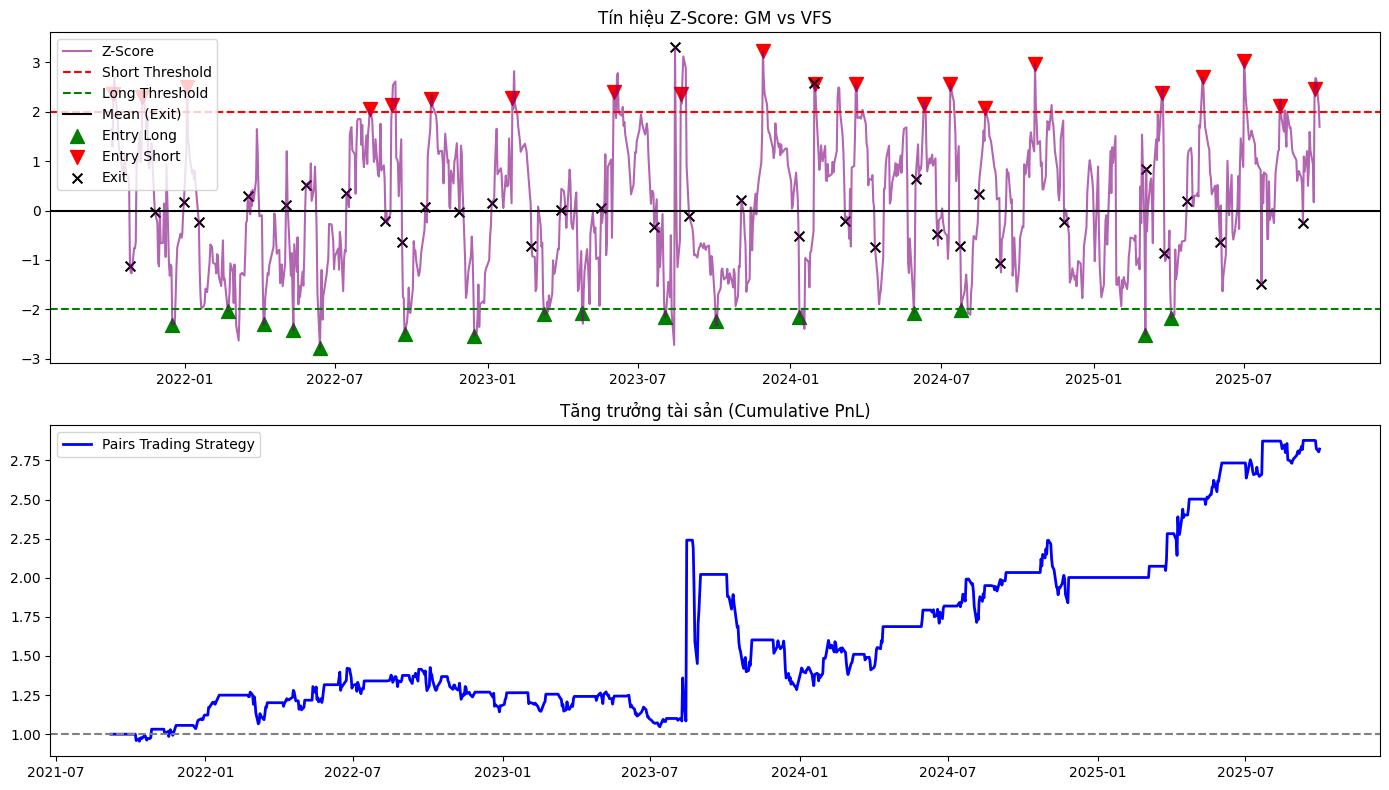

✨ Tổng lợi nhuận: 182.27%
Đang phân tích cặp: TSLA - VFS (Hedge Ratio: -0.0116)
🚀 Đang Backtest cặp TSLA - VFS (Beta = -0.01)...


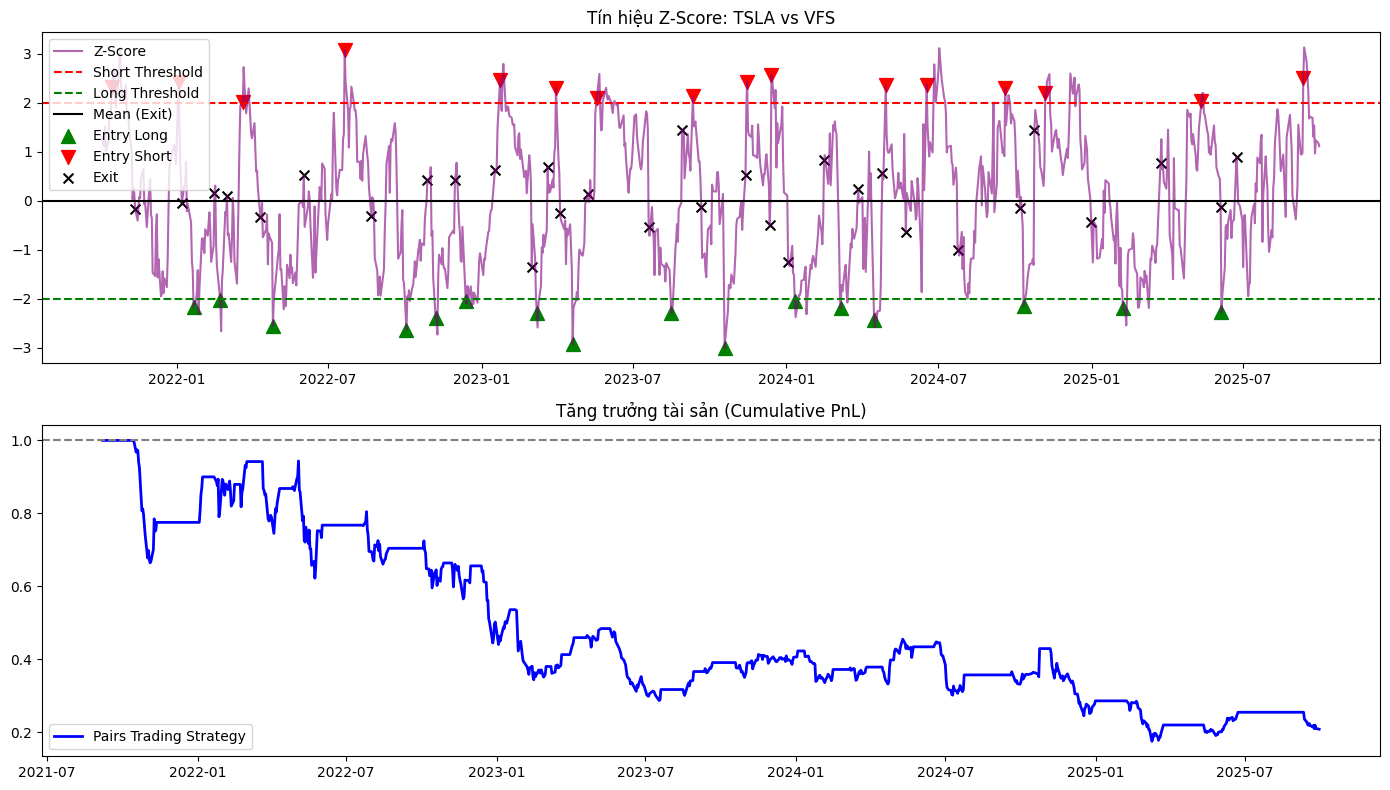

✨ Tổng lợi nhuận: -79.17%
Đang phân tích cặp: LCID - VFS (Hedge Ratio: 0.1174)
🚀 Đang Backtest cặp LCID - VFS (Beta = 0.12)...


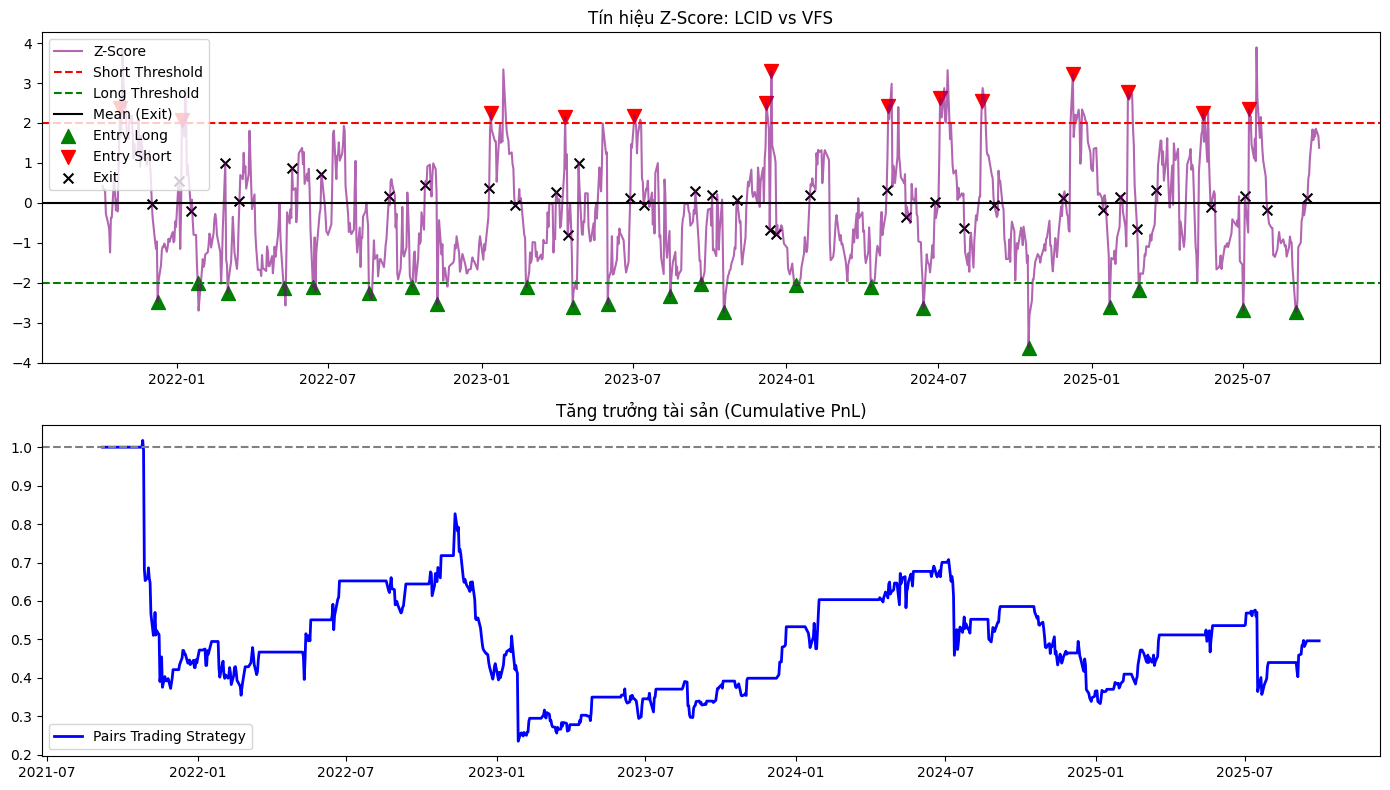

✨ Tổng lợi nhuận: -50.36%
Đang phân tích cặp: F - VFS (Hedge Ratio: 0.1513)
🚀 Đang Backtest cặp F - VFS (Beta = 0.15)...


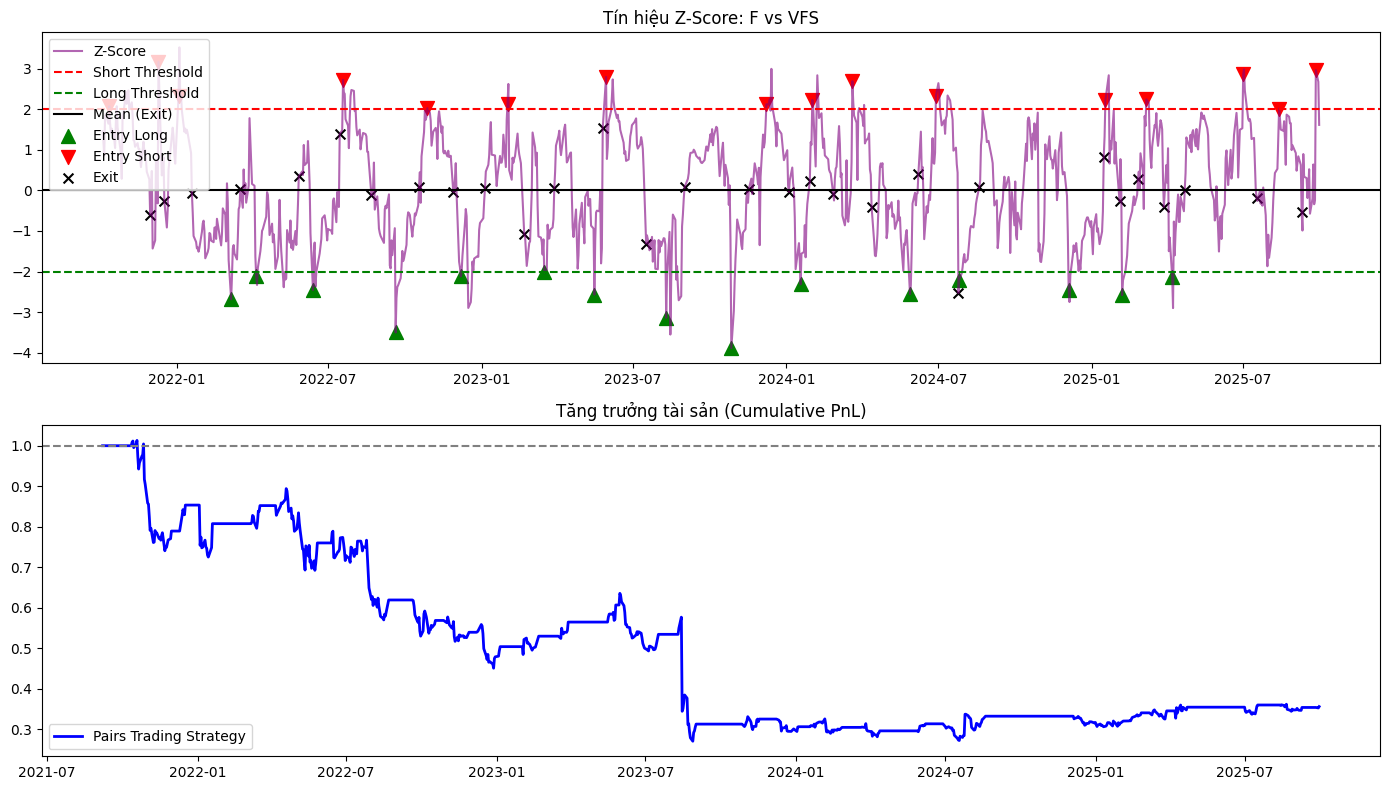

✨ Tổng lợi nhuận: -64.45%
Đang phân tích cặp: V - MA (Hedge Ratio: 1.3838)
🚀 Đang Backtest cặp V - MA (Beta = 1.38)...


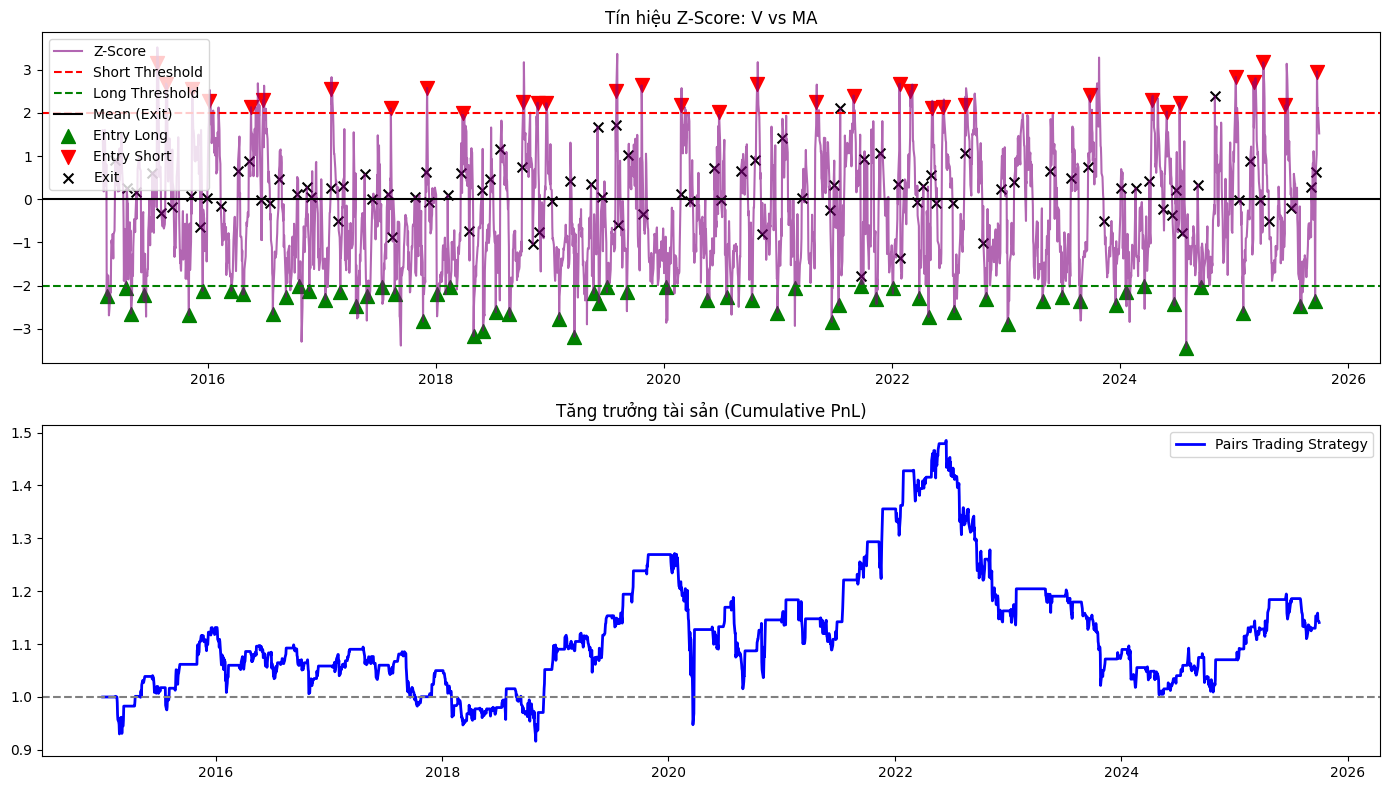

✨ Tổng lợi nhuận: 14.08%
Đang phân tích cặp: NKE - TGT (Hedge Ratio: 0.9764)
🚀 Đang Backtest cặp NKE - TGT (Beta = 0.98)...


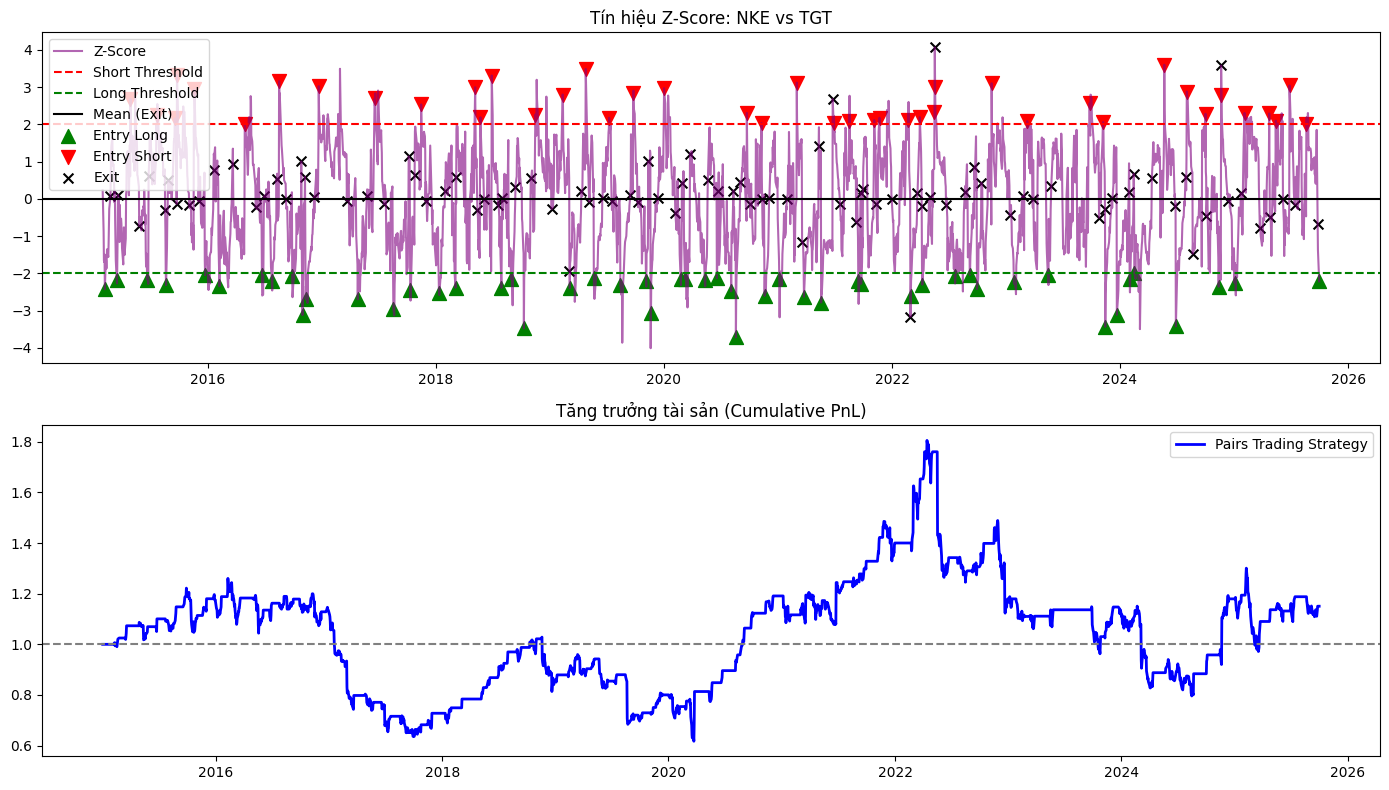

✨ Tổng lợi nhuận: 15.05%
Đang phân tích cặp: AAPL - AMD (Hedge Ratio: 7.4106)
🚀 Đang Backtest cặp AAPL - AMD (Beta = 7.41)...


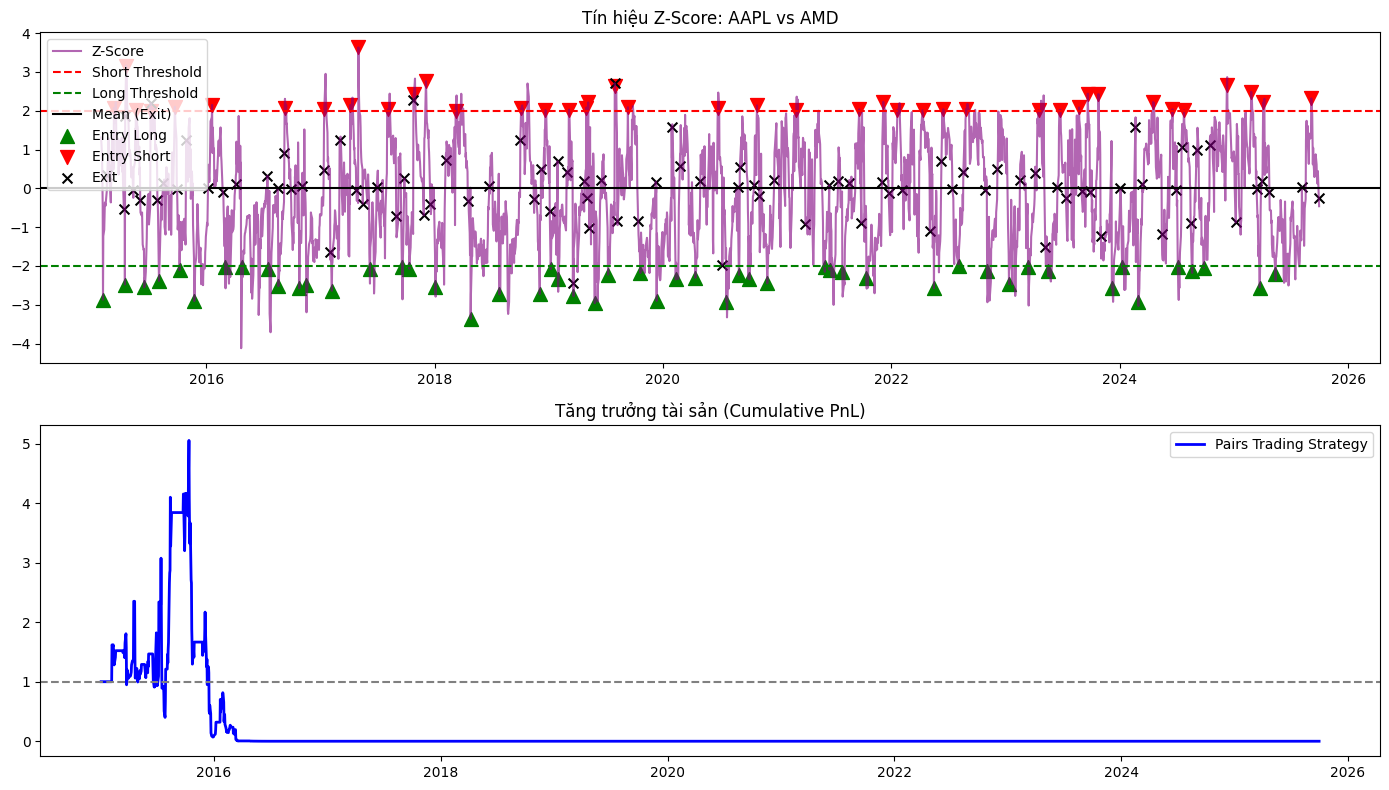

✨ Tổng lợi nhuận: -100.00%
Đang phân tích cặp: AAPL - MSFT (Hedge Ratio: 1.1096)
🚀 Đang Backtest cặp AAPL - MSFT (Beta = 1.11)...


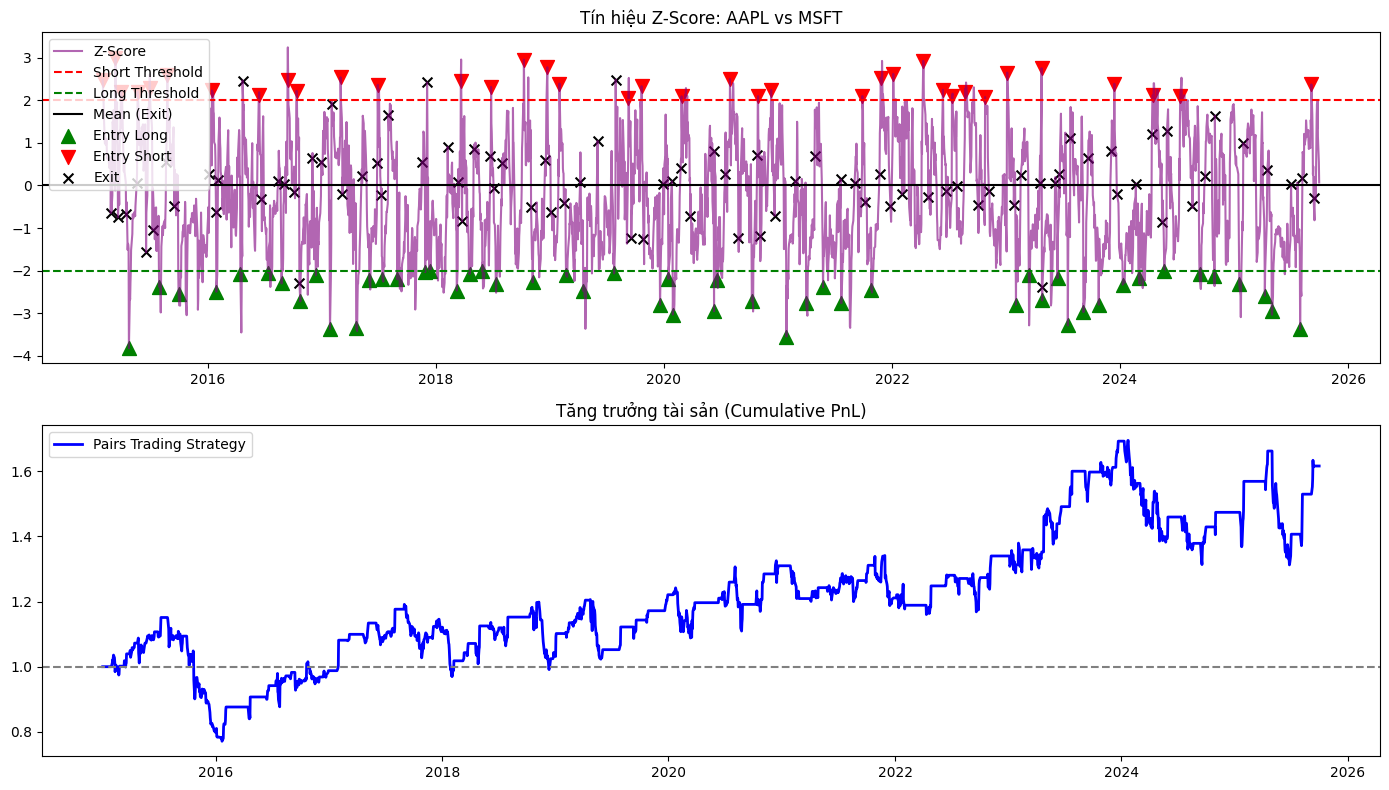

✨ Tổng lợi nhuận: 61.58%
Đang phân tích cặp: KO - COST (Hedge Ratio: 7.7125)
🚀 Đang Backtest cặp KO - COST (Beta = 7.71)...


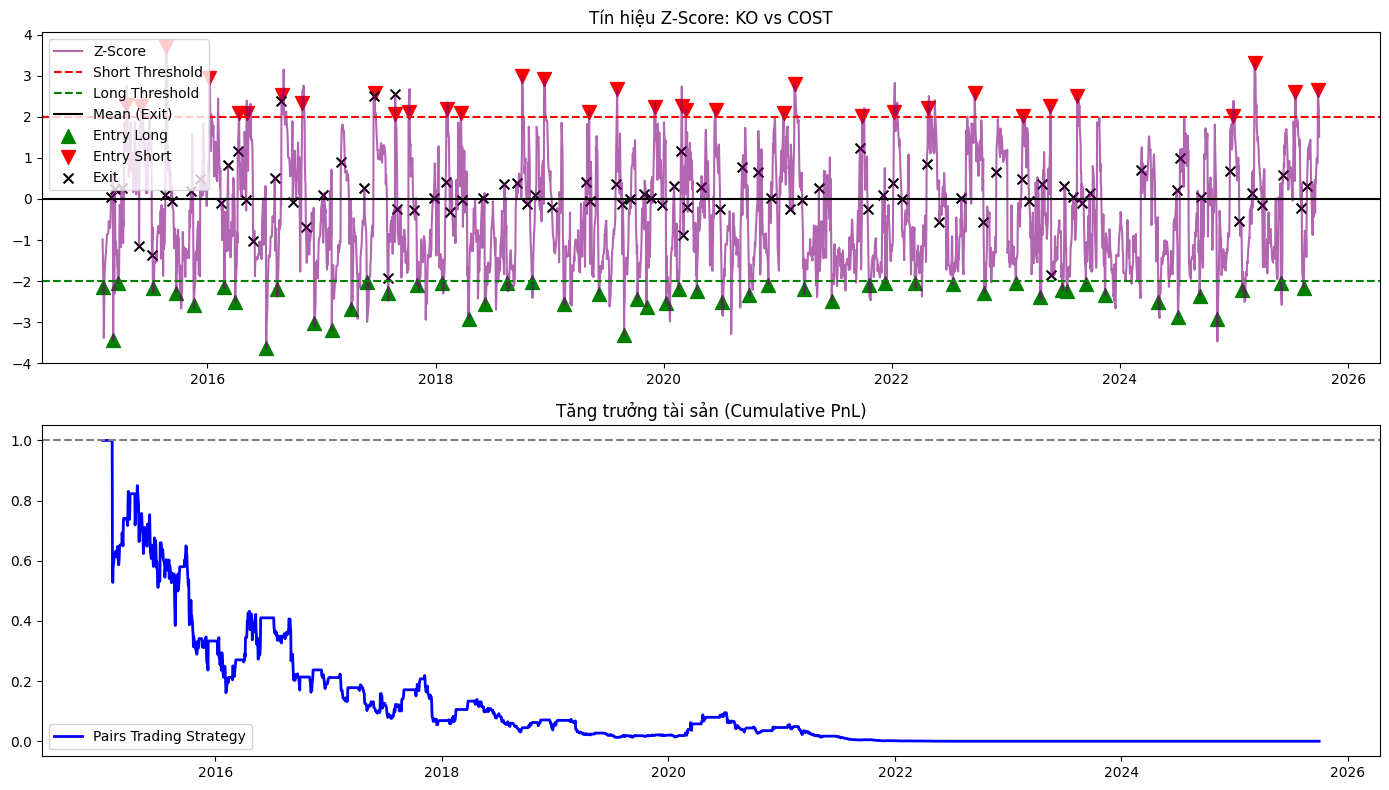

✨ Tổng lợi nhuận: -100.00%
Đang phân tích cặp: MCD - KO (Hedge Ratio: 0.2872)
🚀 Đang Backtest cặp MCD - KO (Beta = 0.29)...


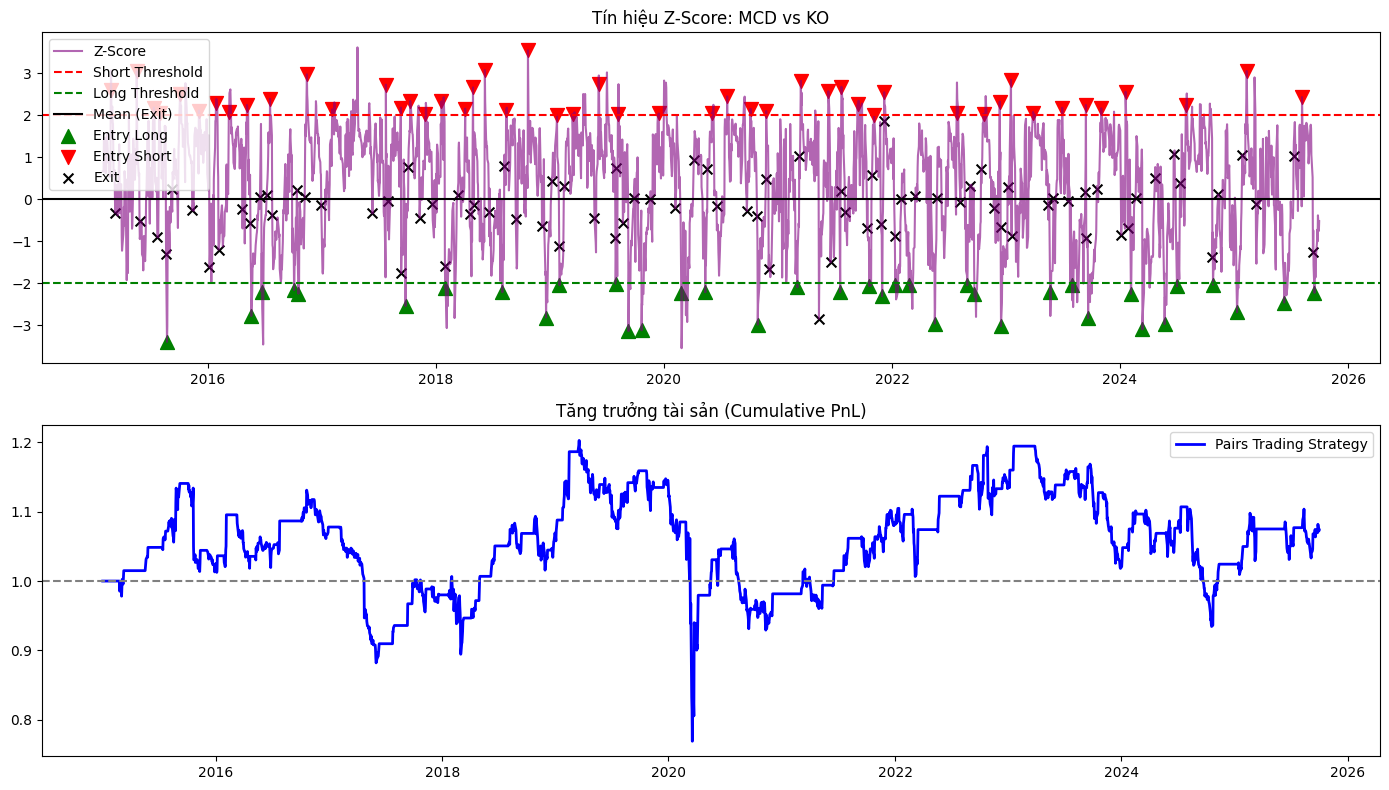

✨ Tổng lợi nhuận: 7.39%
Đang phân tích cặp: GOOG - MSFT (Hedge Ratio: 1.4771)
🚀 Đang Backtest cặp GOOG - MSFT (Beta = 1.48)...


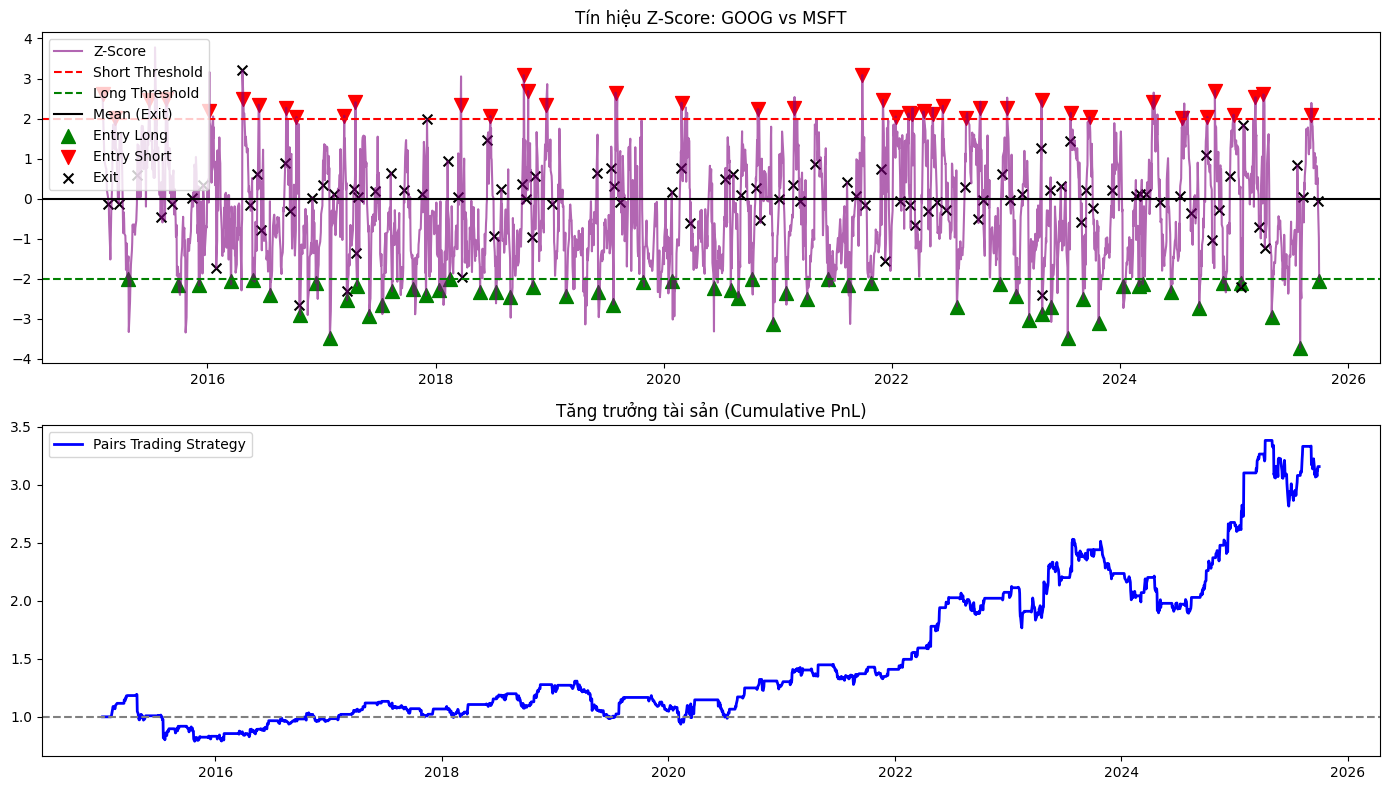

✨ Tổng lợi nhuận: 215.56%
Đang phân tích cặp: NOW - AMD (Hedge Ratio: 4.4356)
🚀 Đang Backtest cặp NOW - AMD (Beta = 4.44)...


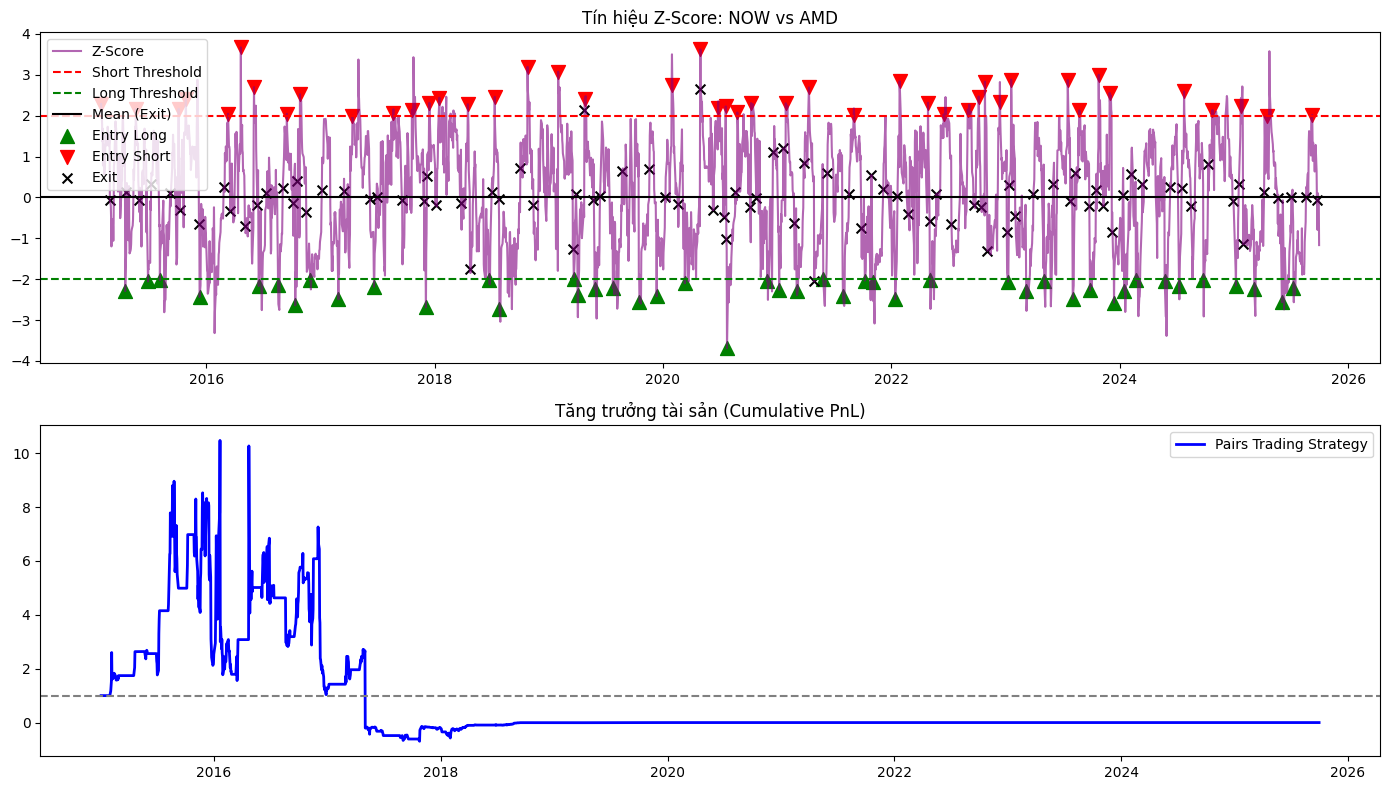

✨ Tổng lợi nhuận: -100.00%
Đang phân tích cặp: CRM - AMZN (Hedge Ratio: 2.9106)
🚀 Đang Backtest cặp CRM - AMZN (Beta = 2.91)...


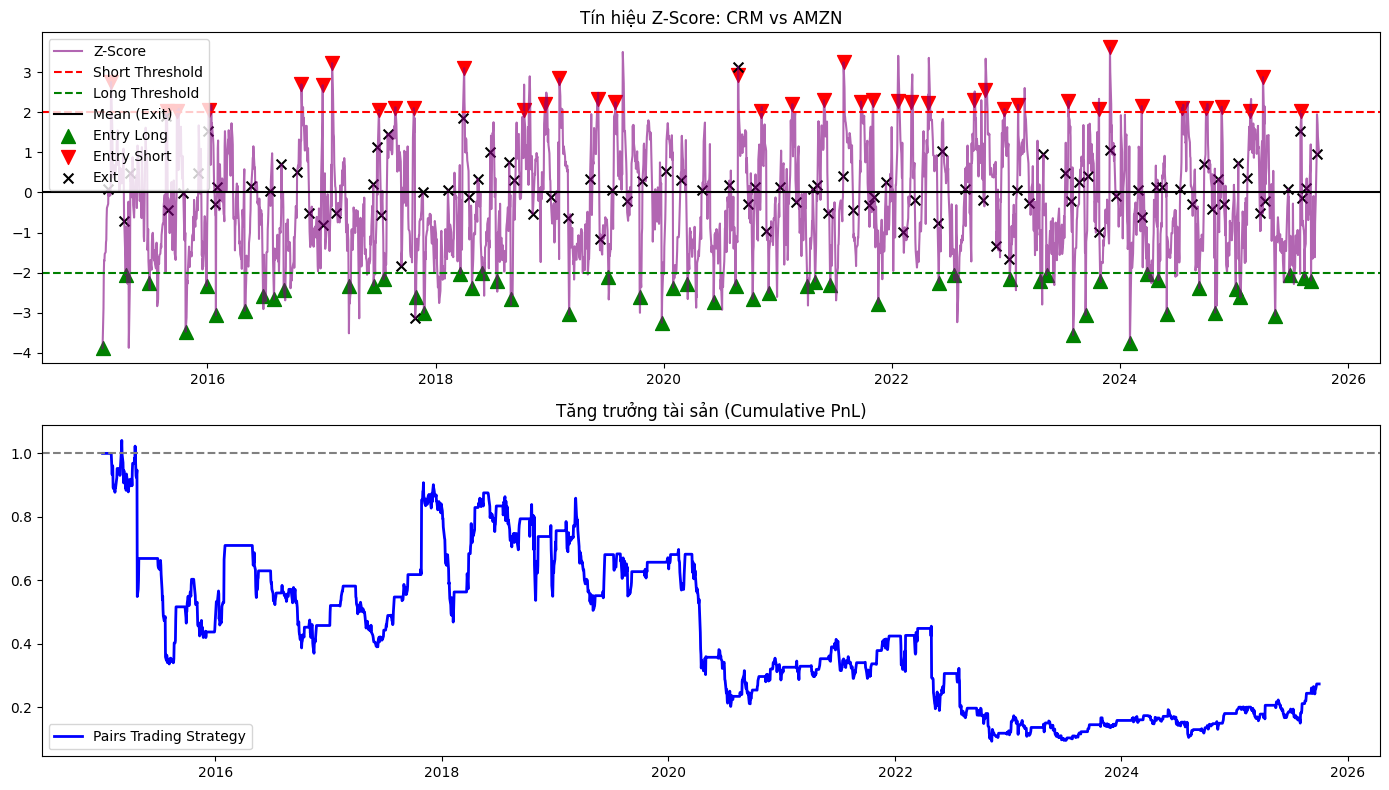

✨ Tổng lợi nhuận: -72.63%
Đang phân tích cặp: AMD - GOOG (Hedge Ratio: 0.0904)
🚀 Đang Backtest cặp AMD - GOOG (Beta = 0.09)...


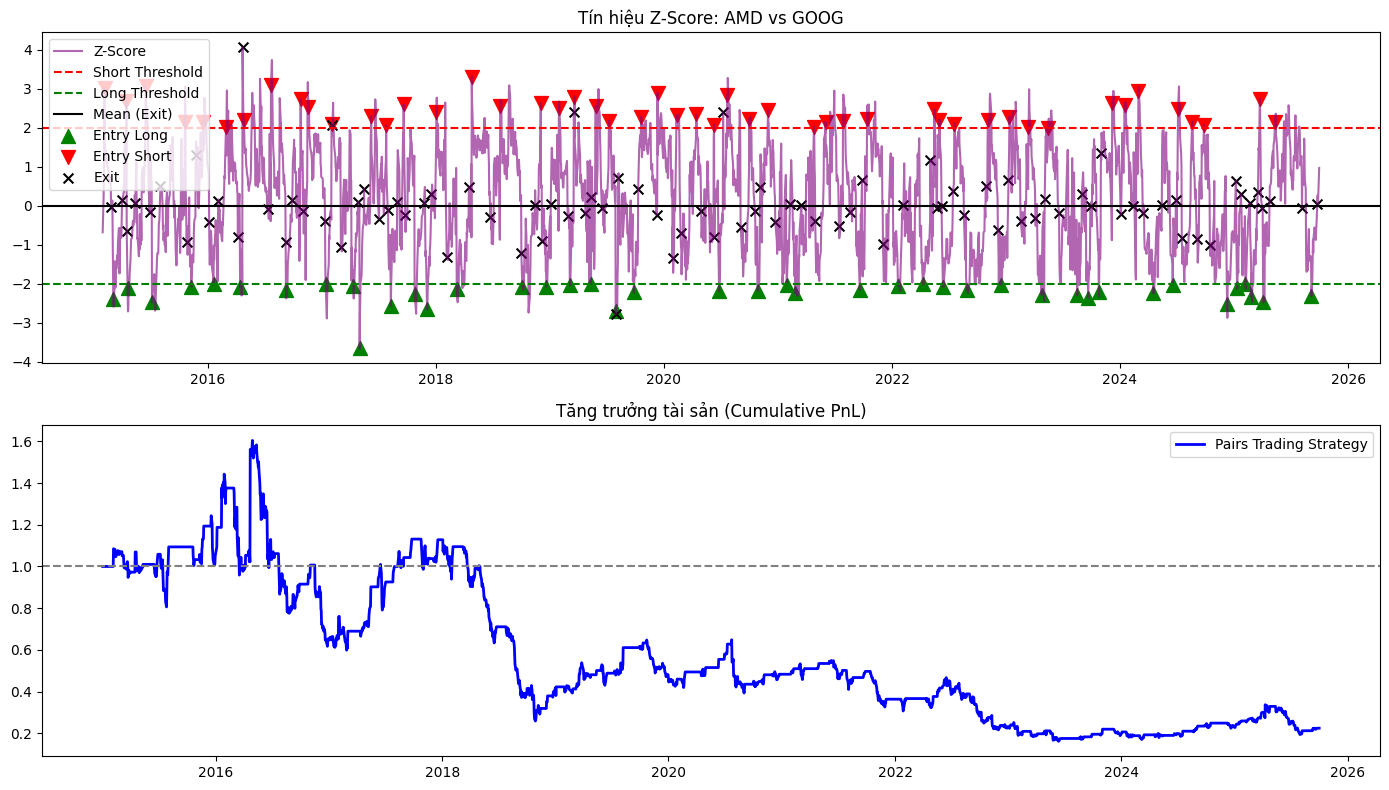

✨ Tổng lợi nhuận: -77.57%
Đang phân tích cặp: NOW - AMZN (Hedge Ratio: 0.8705)
🚀 Đang Backtest cặp NOW - AMZN (Beta = 0.87)...


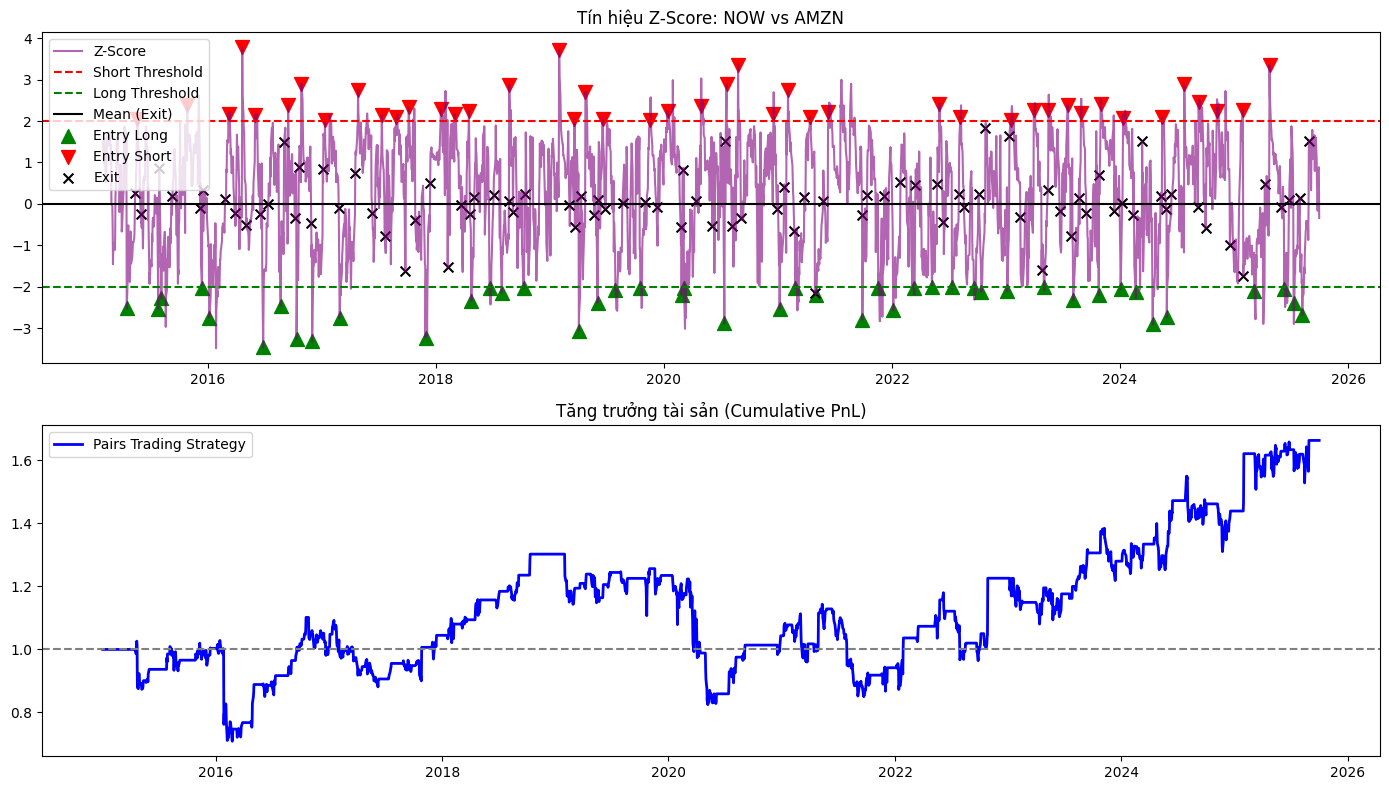

✨ Tổng lợi nhuận: 66.30%
Đang phân tích cặp: TSM - GOOG (Hedge Ratio: 0.7381)
🚀 Đang Backtest cặp TSM - GOOG (Beta = 0.74)...


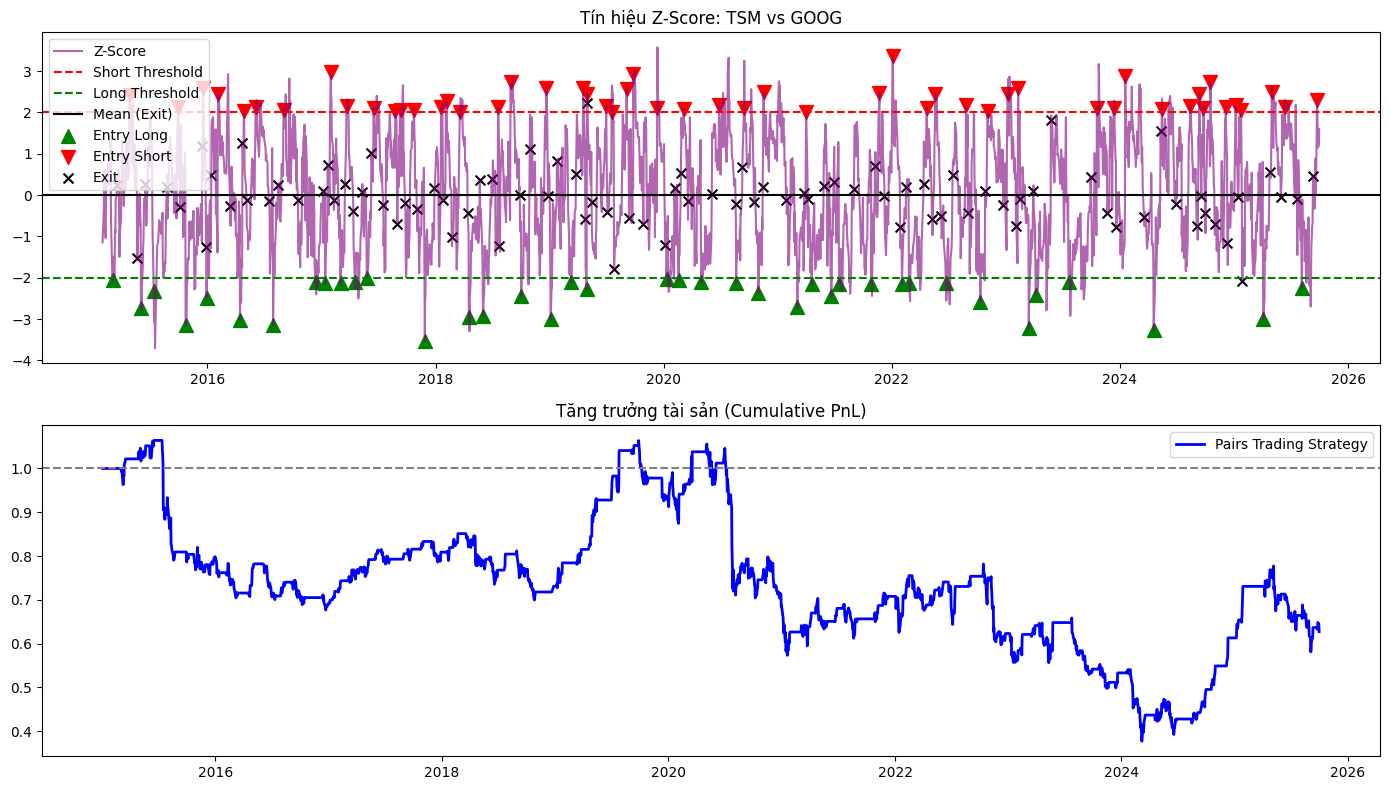

✨ Tổng lợi nhuận: -37.25%
Đang phân tích cặp: PG - LRLCY (Hedge Ratio: 1.6354)
🚀 Đang Backtest cặp PG - LRLCY (Beta = 1.64)...


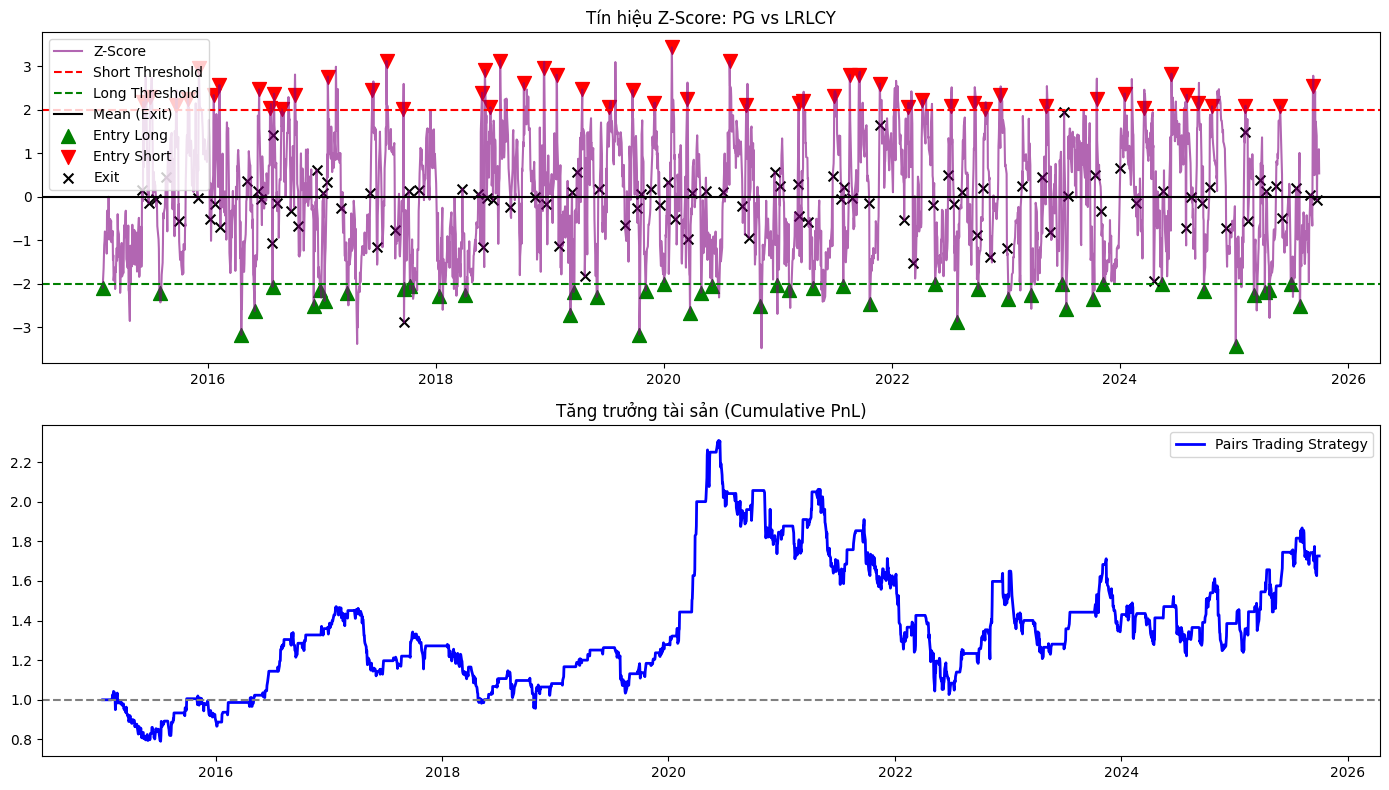

✨ Tổng lợi nhuận: 72.61%
Đang phân tích cặp: AMD - MSFT (Hedge Ratio: 0.1400)
🚀 Đang Backtest cặp AMD - MSFT (Beta = 0.14)...


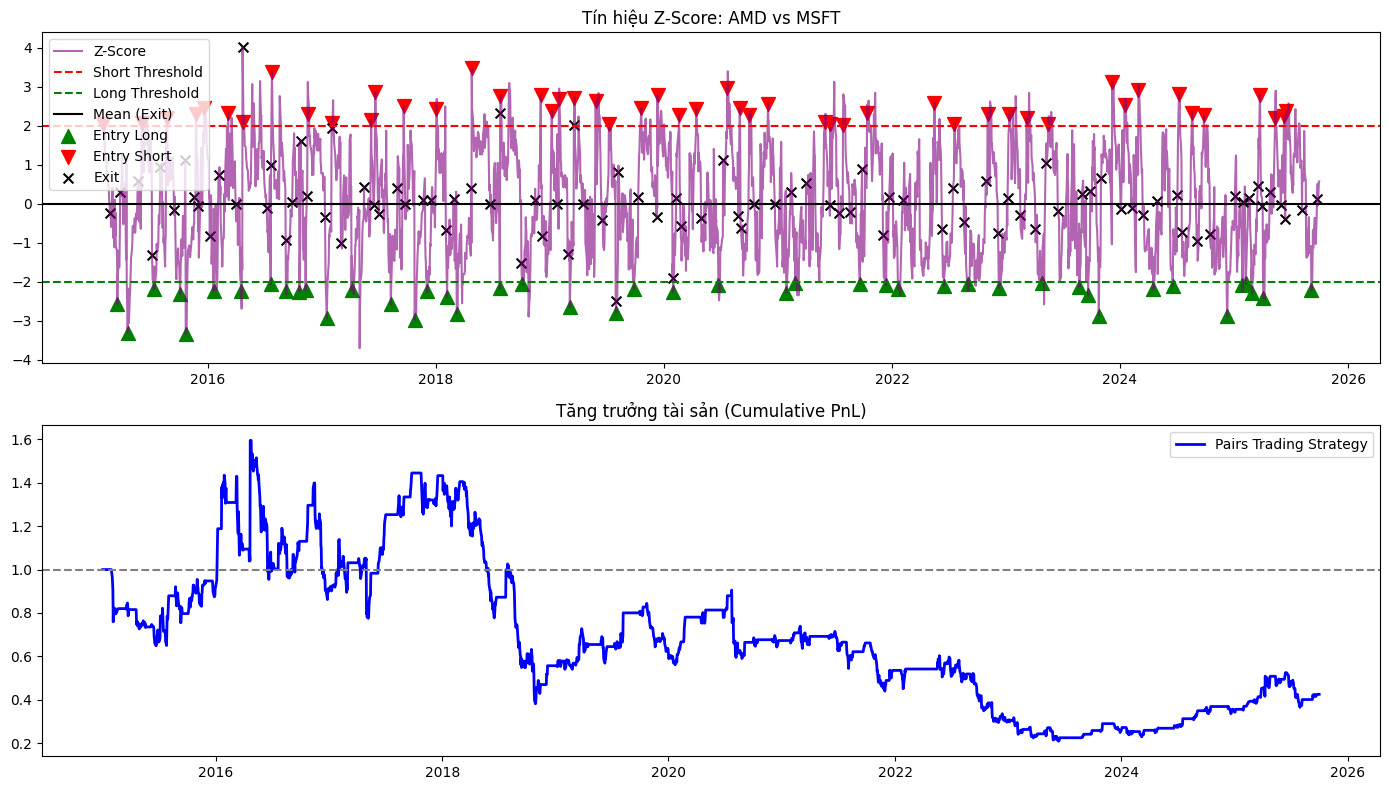

✨ Tổng lợi nhuận: -57.51%
Đang phân tích cặp: NOW - GOOG (Hedge Ratio: 0.4409)
🚀 Đang Backtest cặp NOW - GOOG (Beta = 0.44)...


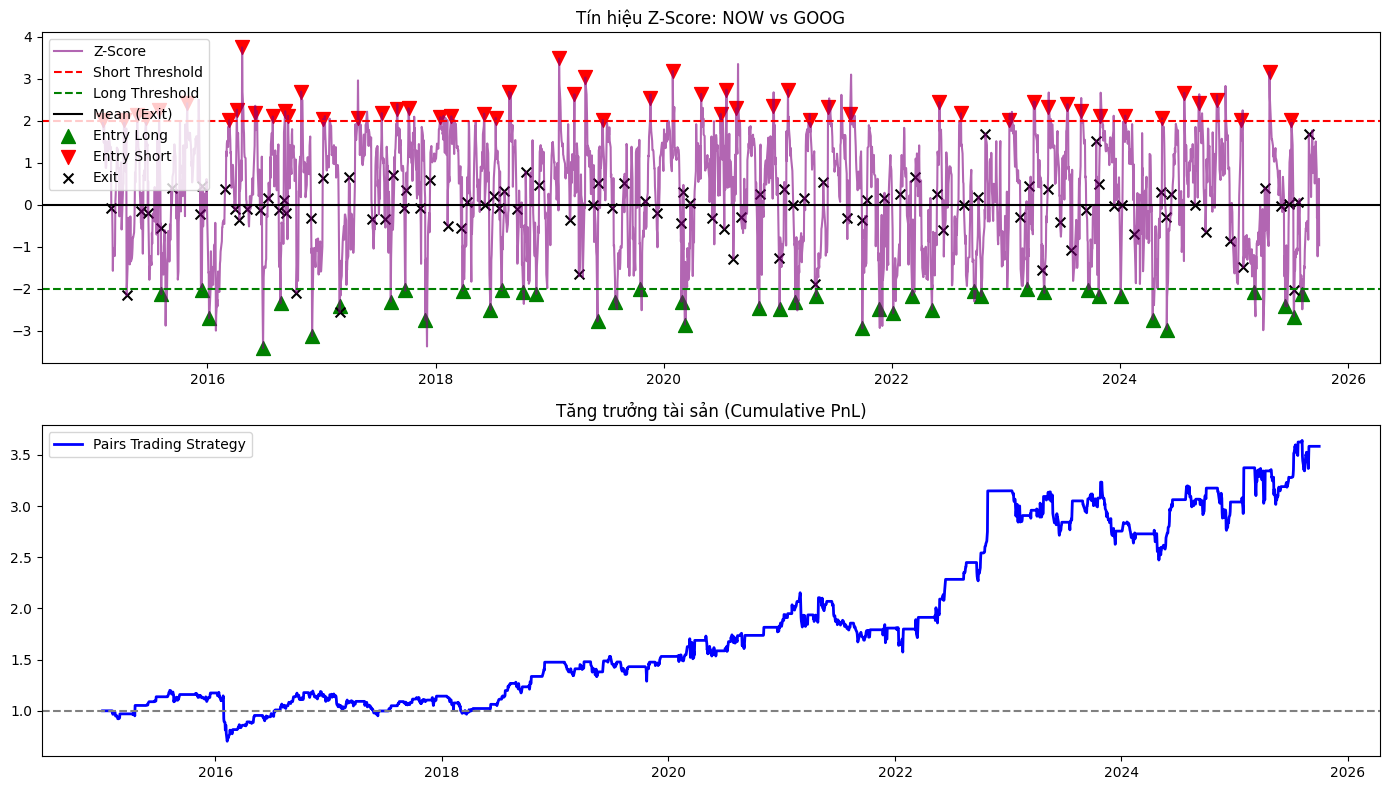

✨ Tổng lợi nhuận: 258.44%
Đang phân tích cặp: AAPL - NOW (Hedge Ratio: 1.5794)
🚀 Đang Backtest cặp AAPL - NOW (Beta = 1.58)...


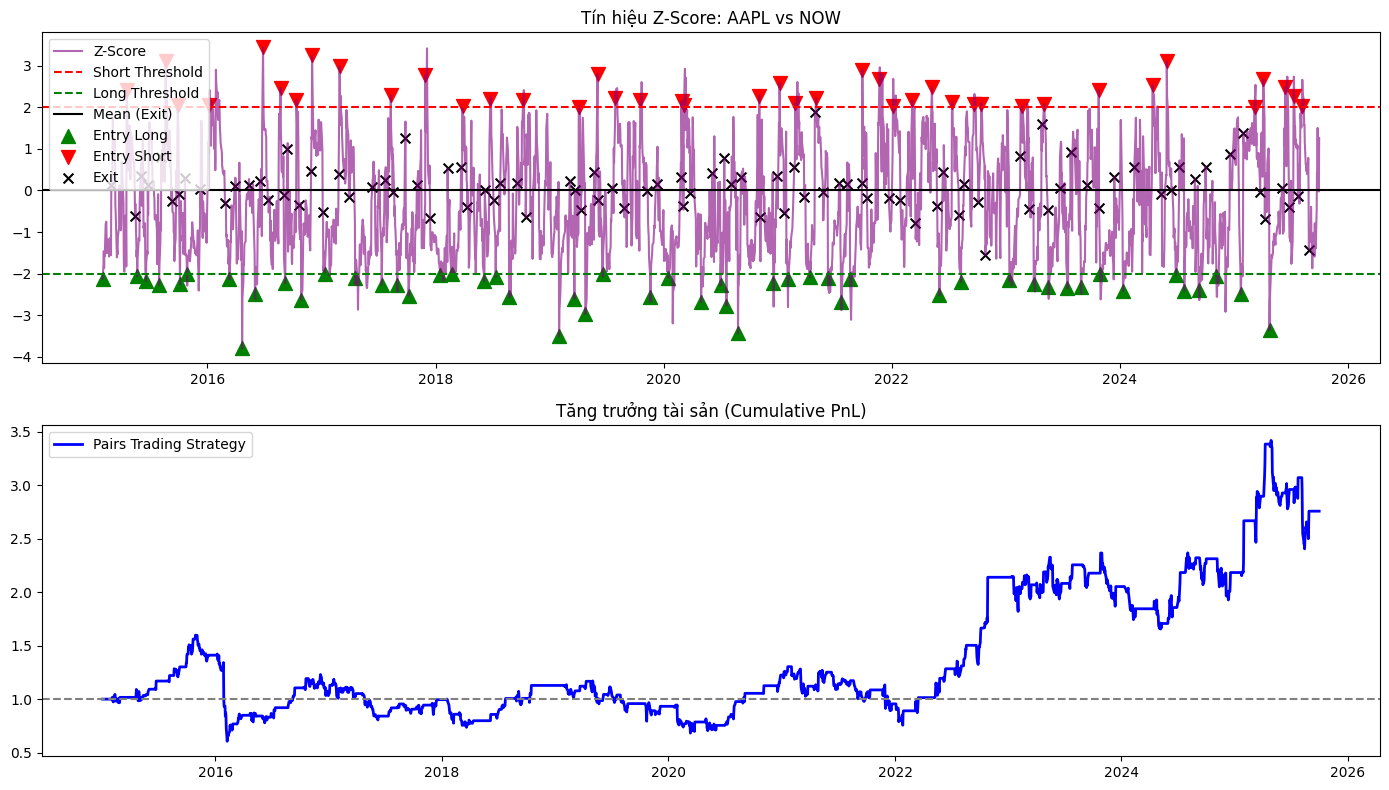

✨ Tổng lợi nhuận: 175.66%
Đang phân tích cặp: WMT - KO (Hedge Ratio: 0.2667)
🚀 Đang Backtest cặp WMT - KO (Beta = 0.27)...


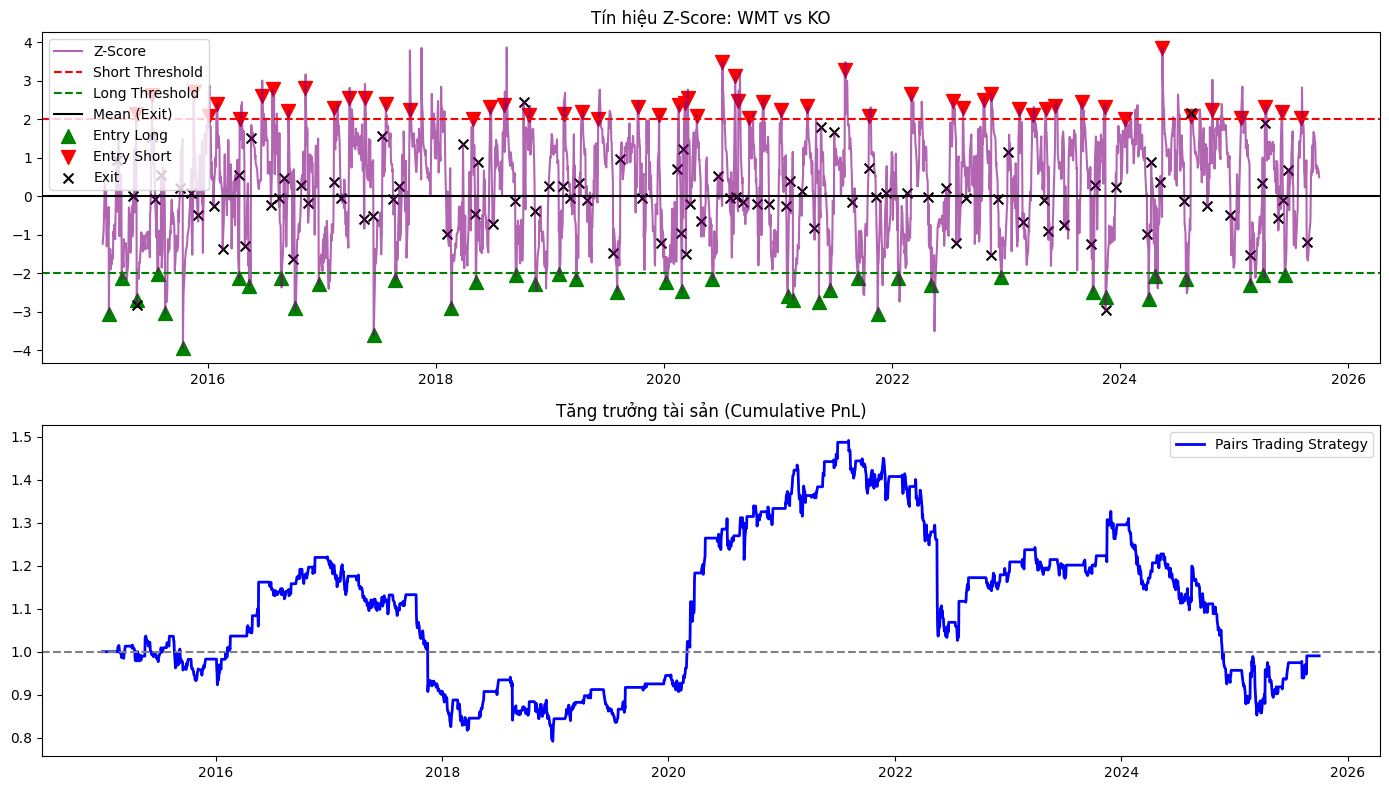

✨ Tổng lợi nhuận: -0.96%
Đang phân tích cặp: CVX - COP (Hedge Ratio: 1.5380)
🚀 Đang Backtest cặp CVX - COP (Beta = 1.54)...


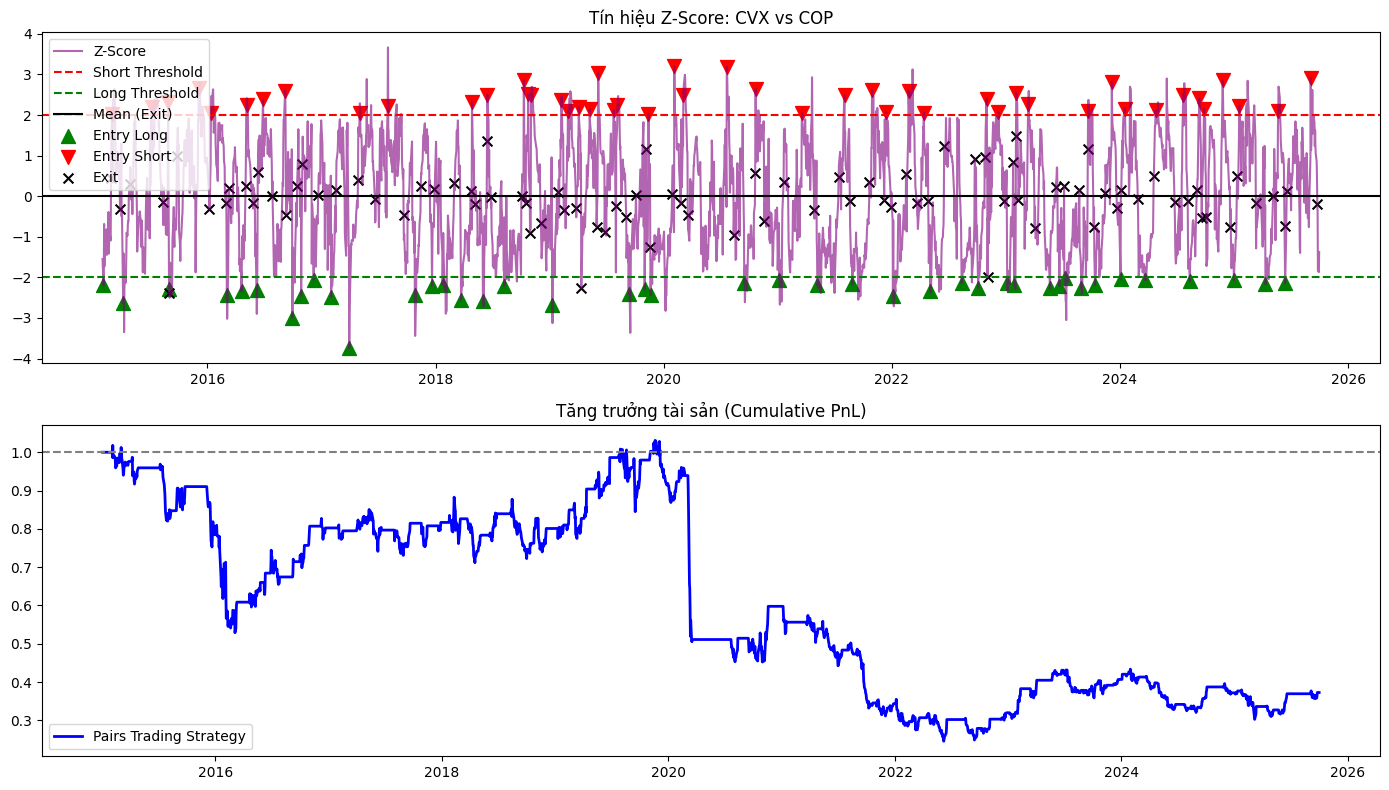

✨ Tổng lợi nhuận: -62.70%
Đang phân tích cặp: HD - LOW (Hedge Ratio: 1.0785)
🚀 Đang Backtest cặp HD - LOW (Beta = 1.08)...


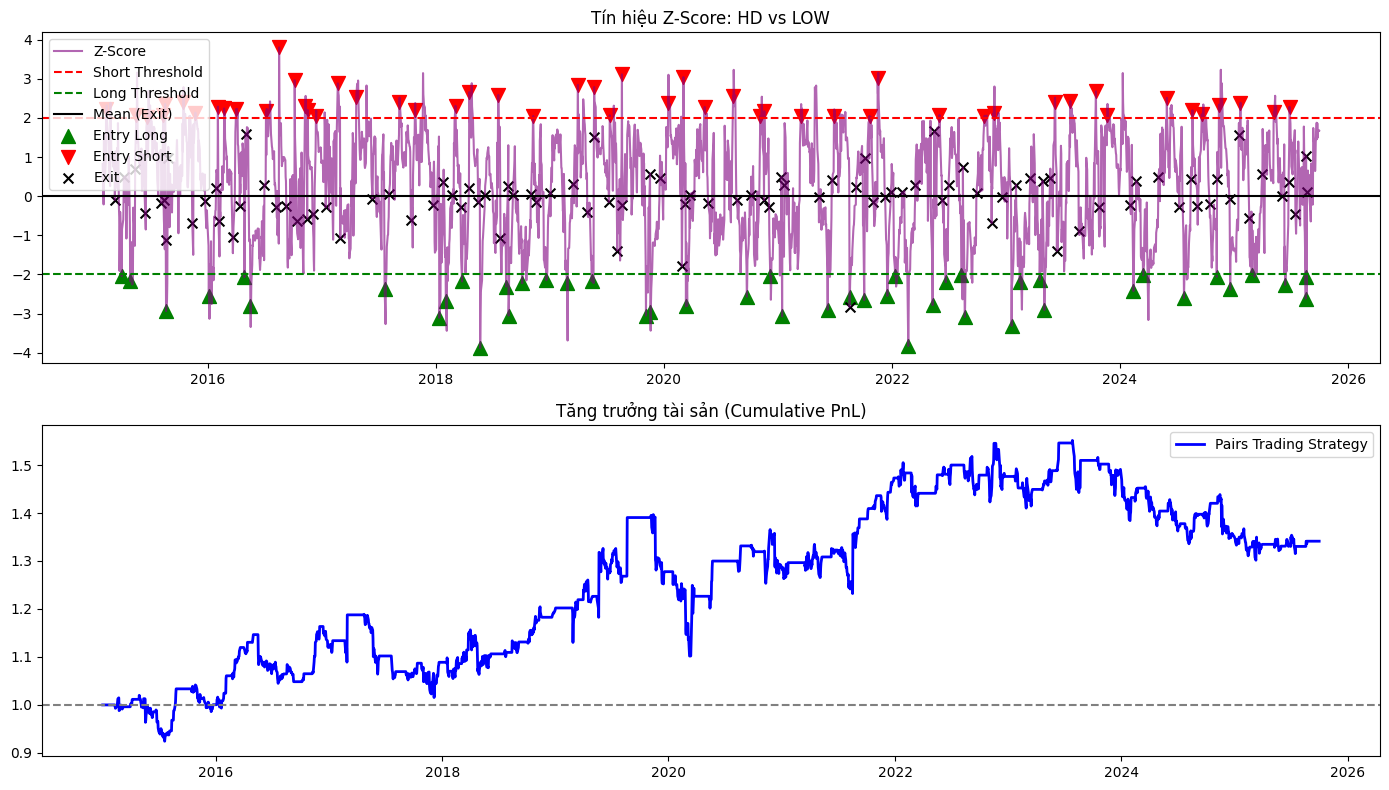

✨ Tổng lợi nhuận: 34.12%
Đang phân tích cặp: SBUX - TGT (Hedge Ratio: 1.1369)
🚀 Đang Backtest cặp SBUX - TGT (Beta = 1.14)...


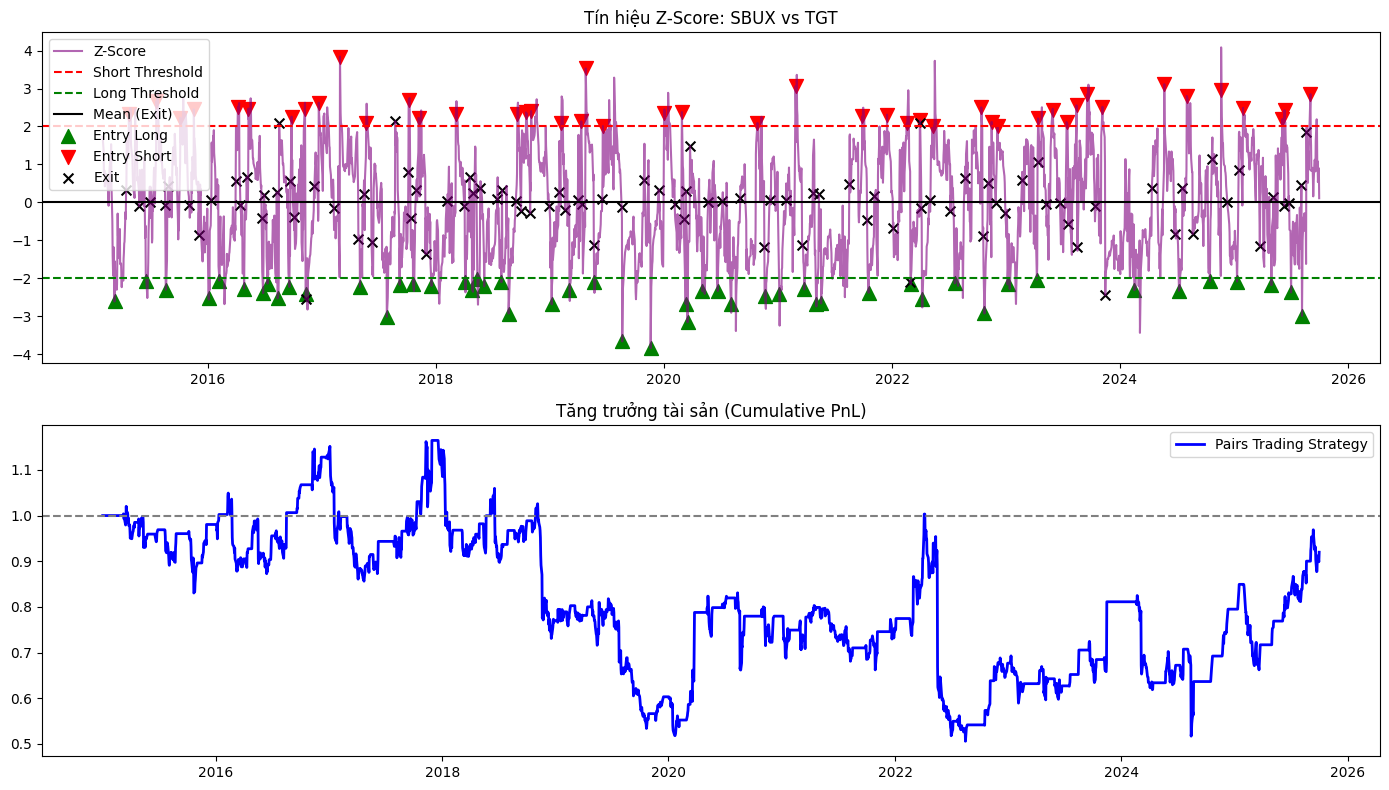

✨ Tổng lợi nhuận: -8.02%
Đang phân tích cặp: CMCSA - DIS (Hedge Ratio: 0.7883)
🚀 Đang Backtest cặp CMCSA - DIS (Beta = 0.79)...


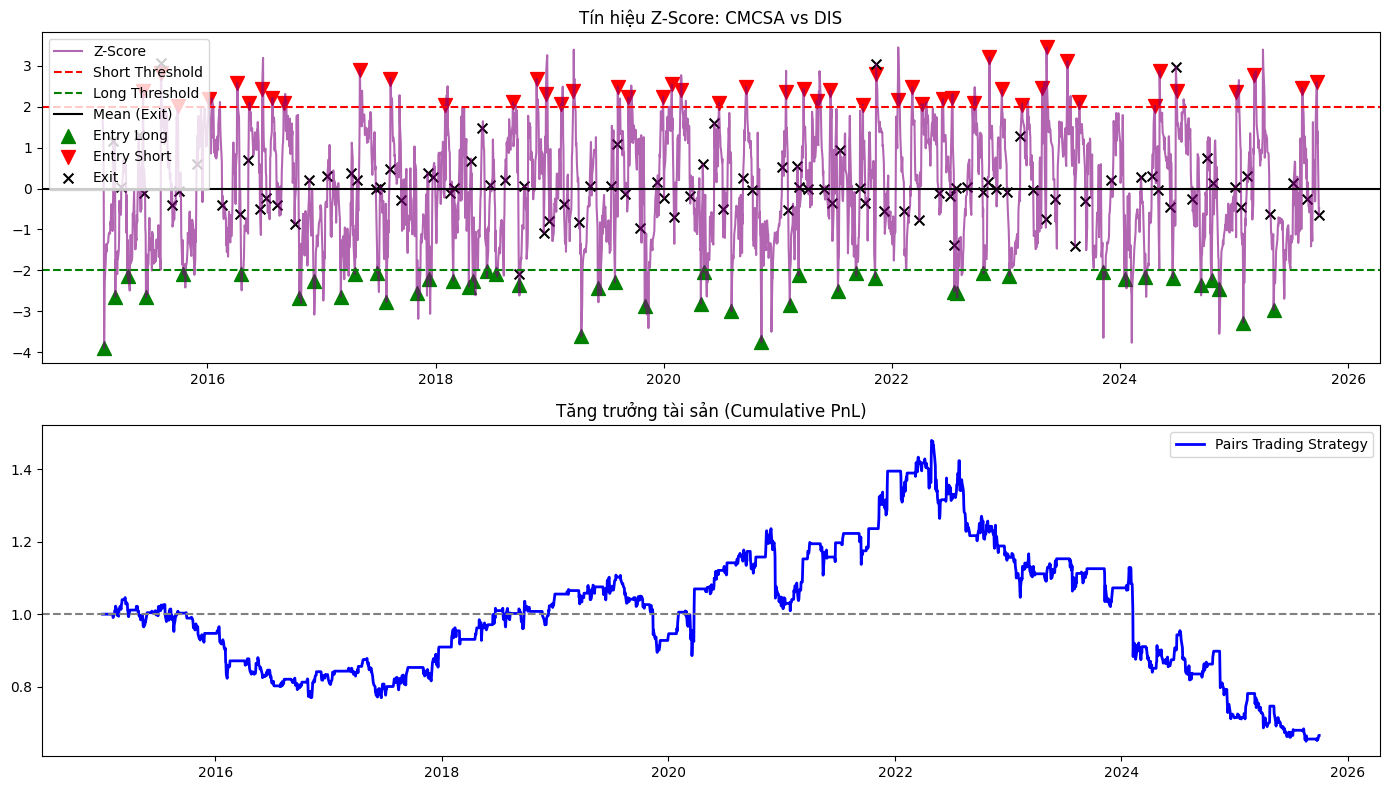

✨ Tổng lợi nhuận: -33.43%


In [ ]:
# --- CHẠY THỬ ---
for index, row in df_economic_pairs.iterrows():
    # 1. Lấy tên Stock 1 và Stock 2 từ dòng hiện tại
    ticker1 = row['Stock 1']
    ticker2 = row['Stock 2']

    # 2. Lấy Hedge Ratio
    hedge_ratio = row['Hedge_Ratio']

    # In ra để kiểm tra đang chạy cặp nào
    print(f"Đang phân tích cặp: {ticker1} - {ticker2} (Hedge Ratio: {hedge_ratio:.4f})")

    # 3. Gọi hàm analyze
    try:
        df_result = analyze_pairs_trading(ticker1, ticker2, hedge_ratio, df_signal_copy)

    except Exception as e:
        print(f"Lỗi khi chạy cặp {ticker1}-{ticker2}: {e}")

**Nhận xét:**
Ví dụ cặp NKE - TGT (Nike vs Target) trong nhóm Bán lẻ - Tiêu dùng (Consumer Discretionary):

**1. Về Z-Score**: Biểu đồ Z-score của cặp này dao động cực kỳ đẹp.
Dao động đều đặn: Đường Z-score (màu tím) liên tục cắt qua trục 0 (Mean), không bị đi lệch quá xa trong thời gian dài.

Tín hiệu vào lệnh dày đặc: Các tam giác xanh (Mua) và đỏ (Bán) xuất hiện liên tục khi Z chạm ngưỡng +/- 2.0. Điều này cho thấy Spread giữa NKE và TGT thường xuyên biến động nhưng luôn có xu hướng quay về trung bình.

Giai đoạn cuối 2022 - đầu 2023: Có một đợt biến động mạnh (Z vọt lên 4.0), nhưng sau đó vẫn quay về 0. Cho thấy mối liên kết kinh tế giữa hai mã này rất bền vững.

**2. Về Lợi Nhuận**: Ổn định và Bền bỉ
- Tăng trưởng tài sản: Đường màu xanh (Cumulative PnL) đi lên khá vững chắc từ 1.0 lên khoảng 1.14 (Lãi 14.08%).

- Drawdown (Sụt giảm): Có một cú sụt giảm mạnh vào năm **2018** (tài sản rớt xuống dưới 0.7). Đây là lúc chiến thuật gặp khó khăn (có thể do thị trường thay đổi cấu trúc). Nhưng sau đó, từ **2019 đến 2022**,lấy lại phong độ và tăng trưởng mạnh mẽ (đỉnh điểm lãi 80% vào **năm 2022**). Giai đoạn **2023-2024**: Lợi nhuận đi ngang và sụt giảm nhẹ, nhưng vẫn giữ được mức lãi dương tổng thể.

**3. Đánh giá Tổng quan**

Độ tin cậy: CAO. Cặp này cùng nhóm ngành Tiêu dùng, cùng chịu ảnh hưởng của sức mua người dân Mỹ, nên việc chúng đi cùng nhau là có cơ sở kinh tế vững chắc.

Hiệu quả: KHÁ. Mức lãi 14% tuy không phải là "siêu lợi nhuận", nhưng nó an toàn và ổn định hơn nhiều.

**Tìm các mã có lợi nhuận cao sau khi đã áp dụng chiến lược trên**

In [ ]:
import pandas as pd
import numpy as np

# --- HÀM BACKTEST KHÔNG VẼ HÌNH ---
def backtest_pair_silent(ticker1, ticker2, hedge_ratio, data_dict, entry_threshold=2.0, exit_threshold=0.0, stop_loss=4.0):
    # Kiểm tra dữ liệu
    if ticker1 not in data_dict or ticker2 not in data_dict:
        return None

    # Lấy dữ liệu
    col1 = 'Adj Close' if 'Adj Close' in data_dict[ticker1] else 'Close'
    col2 = 'Adj Close' if 'Adj Close' in data_dict[ticker2] else 'Close'

    # Gộp dữ liệu
    try:
        df = pd.concat([data_dict[ticker1][col1], data_dict[ticker2][col2]], axis=1, join='inner')
        df.columns = [ticker1, ticker2]
    except:
        return None # Trả về None nếu lỗi gộp data

    # Tính Spread & Z-Score
    df['Spread'] = df[ticker1] - hedge_ratio * df[ticker2]

    window = 20
    rolling_mean = df['Spread'].rolling(window=window).mean()
    rolling_std = df['Spread'].rolling(window=window).std()
    df['Z_Score'] = (df['Spread'] - rolling_mean) / rolling_std

    # Logic Vào lệnh (State Machine)
    position = 0
    positions = []

    z_scores = df['Z_Score'].values

    for i in range(len(df)):
        z = z_scores[i]

        if np.isnan(z):
            positions.append(0)
            continue

        if position == 0:
            if z < -entry_threshold and z > -stop_loss: position = 1
            elif z > entry_threshold and z < stop_loss: position = -1
        elif position == 1:
            if z >= -exit_threshold: position = 0
            elif z <= -stop_loss: position = 0
        elif position == -1:
            if z <= exit_threshold: position = 0
            elif z >= stop_loss: position = 0

        positions.append(position)

    df['Position'] = positions

    # Tính Lợi nhuận
    ret1 = df[ticker1].pct_change()
    ret2 = df[ticker2].pct_change()

    df['Spread_Return'] = ret1 - hedge_ratio * ret2
    df['Strategy_Return'] = df['Position'].shift(1) * df['Spread_Return']
    df['Cumulative_Return'] = (1 + df['Strategy_Return'].fillna(0)).cumprod()

    # Kết quả cuối cùng
    total_return = df['Cumulative_Return'].iloc[-1] - 1

    # Đếm số lệnh (Số lần chuyển từ 0 sang khác 0)
    pos_arr = np.array(positions)
    num_trades = np.sum((pos_arr[:-1] == 0) & (pos_arr[1:] != 0))

    return {
        'Total_Return': total_return,
        'Num_Trades': num_trades
    }

# --- 2. CHẠY VÒNG LẶP VÀ TỔNG HỢP VÀO DATAFRAME ---
summary_data = []

print(f"⏳ Đang xử lý {len(df_economic_pairs)} cặp...")

for index, row in df_economic_pairs.iterrows():
    t1 = row['Stock 1']
    t2 = row['Stock 2']
    beta = row['Hedge_Ratio']

    # Gọi hàm
    result = backtest_pair_silent(t1, t2, beta, df_signal_copy)

    if result is not None:
        summary_data.append({
            'Stock_1': t1,
            'Stock_2': t2,
            'Hedge_Ratio': beta,
            'Num_Trades': result['Num_Trades'],     # Số lệnh đã đánh
            'Total_Return': result['Total_Return']  # Tổng lãi/lỗ
        })

# --- 3. TẠO DF VÀ SẮP XẾP ---
df_summary = pd.DataFrame(summary_data)

df_summary['Total_Return'] = df_summary['Total_Return'] * 100

# Sắp xếp giảm dần theo lợi nhuận
df_summary = df_summary.sort_values(by='Total_Return', ascending=False).reset_index(drop=True)

# Format lại cột % cho đẹp (chỉ để hiển thị)
pd.options.display.float_format = '{:.2f}'.format

print("✅ Đã xong! Dưới đây là các cặp tốt nhất:")
display(df_summary)

⏳ Đang xử lý 25 cặp...
✅ Đã xong! Dưới đây là các cặp tốt nhất:


,Stock_1,Stock_2,Hedge_Ratio,Num_Trades,Total_Return
0,NOW,GOOG,0.44,97,258.44
1,GOOG,MSFT,1.48,98,215.56
2,GM,VFS,-0.43,37,182.27
3,AAPL,NOW,1.58,94,175.66
4,PG,LRLCY,1.64,99,72.61
5,NOW,AMZN,0.87,89,66.30
6,AAPL,MSFT,1.11,88,61.58
7,HD,LOW,1.08,98,34.12
8,NKE,TGT,0.98,94,15.05
9,V,MA,1.38,93,14.08


## **4. Backtesting**

Sau khi xây được chiến lược rồi, cần backtest lại để:

**1. Để đánh giá hiệu quả mô hình trong môi trường giả lập thực tế**

**2. Để ngăn chặn lỗi "Nhìn trước tương lai" (Look-ahead Bias)**

Backtest nghiêm ngặt (như việc chia tập Train/Test và Shift ngày) giúp ngăn chặn việc sử dụng thông tin tương lai ("No use of future information"), từ đó loại bỏ thiên kiến nhìn trước ("Prevents look-ahead bias").

**3. Để tối ưu hóa tham số (Tuning) một cách khoa học**

**4. Để kiểm chứng sự bền vững của mối quan hệ**

Backtest giúp kiểm tra xem mối liên kết đó có duy trì trong tương lai hay không, hay là sẽ bị phá vỡ (Broken Pair) khi thị trường thay đổi.

Nếu không Backtest, ta sẽ đem tiền thật đi đánh cược vào một mối quan hệ có thể đã "chết" từ lâu.

### **1. Chia tập Train, Test**

### **2. Hiệu chỉnh tập Validation**

### **3. Chạy trên tập test**

**Hàm backtest gồm cả 3 bước trên:**

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [ ]:
from operator import pos
from re import split
def backtest_pairs_split(ticker1, ticker2, data_dict, split_ratio = 0.8):
  print(f"⚔️ Backtest cặp {ticker1} - {ticker2} (Chia Train/Test: {split_ratio:.0%})...")

  # 1. CHUẨN BỊ DỮ LIỆU CHUNG
  # Lấy giá Close/Adj Close
  col1 = 'Adj Close' if 'Adj Close' in data_dict[ticker1] else 'Close'
  col2 = 'Adj Close' if 'Adj Close' in data_dict[ticker2] else 'Close'

  # Gộp vào 1 bảng (Inner Join để khớp ngày)
  df = pd.concat([data_dict[ticker1][col1], data_dict[ticker2][col2]], axis=1, join='inner')
  df.columns = [ticker1, ticker2]

  # 2. CHIA TẬP TRAIN / TEST
  # Tính điểm cắt (Index)
  split_index = int(len(df) * split_ratio)

  df_train = df.iloc[:split_index].copy()
  df_test = df.iloc[split_index:].copy()

  print(f"- Train: {df_train.index[0].date()} -> {df_train.index[-1].date()} ({len(df_train)} ngày)")
  print(f"- Test : {df_test.index[0].date()} -> {df_test.index[-1].date()} ({len(df_test)} ngày)")

  # ---------------------------------------------------------
  # GIAI ĐOẠN 1: TRAINING (Học Mô Hình)
  # ---------------------------------------------------------
  # Tìm Hedge Ratio chỉ dựa trên dữ liệu quá khứ
  X_train = sm.add_constant(df_train[ticker2])
  Y_train = df_train[ticker1]
  model = sm.OLS(Y_train, X_train).fit()

  # Lưu lại tham số để dùng sau
  hedge_ratio = model.params[ticker2]
  intercept = model.params['const']

  print(f"-> Kết quả Training: Hedge Ratio: {hedge_ratio:.4f}")

  # ---------------------------------------------------------
  # GIAI ĐOẠN 2: TESTING (Áp Dụng Thực Tế)
  # ---------------------------------------------------------
  # Dùng Hedge Ratio CŨ để tính Spread MỚI
  # Spread = Price1 - (beta*Price2 + intercept)
  df_test['Spread'] = df_test[ticker1] - (hedge_ratio * df_test[ticker2] + intercept)

  # Tính Z-score cho tập Test
  window = 20
  df_test['Z_Score'] = (df_test['Spread'] - df_test['Spread'].rolling(window).mean()) / df_test['Spread'].rolling(window).std()

  # 3. LOGIC GIAO DỊCH TRÊN TẬP TEST
  # Copy lại logic State Machine
  position = 0
  positions = []
  entry_threshold = 2.0
  exit_threshold = 0.0

  for i in range(len(df_test)):
    z = df_test['Z_Score'].iloc[i]

    if pd.isna(z):
      positions.append(0)
      continue

    if position == 0:
      if z < -entry_threshold:
        position = 1          # Long Spread
      elif z > entry_threshold:
        position = -1         # Short Spread
    elif position == 1:
      if z >= exit_threshold:
        position = 0          # Chốt lời Long
    elif position == -1:
      if z <= -exit_threshold:
        position = 0          # Chốt lời Short

    positions.append(position)

  df_test['Position'] = positions

  # 4. TÍNH LÃI TRÊN TẬP TEST
  # PnL ~ Ret1 - Beta * Ret2
  ret1 = df_test[ticker1].pct_change()
  ret2 = df_test[ticker2].pct_change()
  df_test['Spread_Return'] = ret1 - hedge_ratio * ret2

  # Shift ngày để không bị look-ahead bias
  df_test['Strategy_Return'] = df_test['Position'].shift(1) * df_test['Spread_Return']
  df_test['Cumulative_PnL'] = (1 + df_test['Strategy_Return'].fillna(0)).cumprod()

  # 5. VẼ BIỂU ĐỒ KẾT QUẢ
  plt.figure(figsize=(14, 6))
  plt.plot(df_test.index, df_test['Cumulative_PnL'], label='Lợi Nhuận Trên Tập Test', color='blue', lw=2)
  plt.axhline(1, color='gray', linestyle='--')
  plt.title(f'Kết quả Backtest: {ticker1} vs {ticker2} (Out-of-Sample)')
  plt.ylabel('Tăng trưởng tài sản')
  plt.legend()
  plt.show()

  total_return = df_test['Cumulative_PnL'].iloc[-1] - 1
  print(f"✨ Tổng lợi nhuận trên tập Test: {total_return:.2%}")

  return df_test

**Chạy các cặp trong df_economic_pairs với tham số tuning tốt nhất**

Đang phân tích cặp: GM - VFS (Hedge Ratio: -0.4274)
⚔️ Backtest cặp GM - VFS (Chia Train/Test: 80%)...
- Train: 2021-09-07 -> 2024-12-03 (816 ngày)
- Test : 2024-12-04 -> 2025-09-30 (205 ngày)
-> Kết quả Training: Hedge Ratio: -0.3545


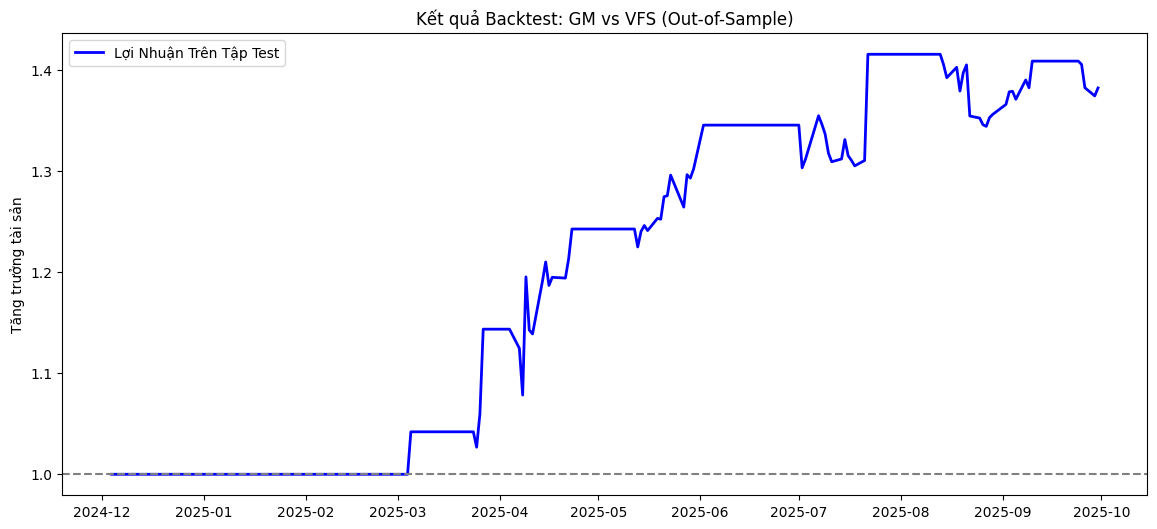

✨ Tổng lợi nhuận trên tập Test: 38.24%
Đang phân tích cặp: TSLA - VFS (Hedge Ratio: -0.0116)
⚔️ Backtest cặp TSLA - VFS (Chia Train/Test: 80%)...
- Train: 2021-09-07 -> 2024-12-03 (816 ngày)
- Test : 2024-12-04 -> 2025-09-30 (205 ngày)
-> Kết quả Training: Hedge Ratio: 1.3037


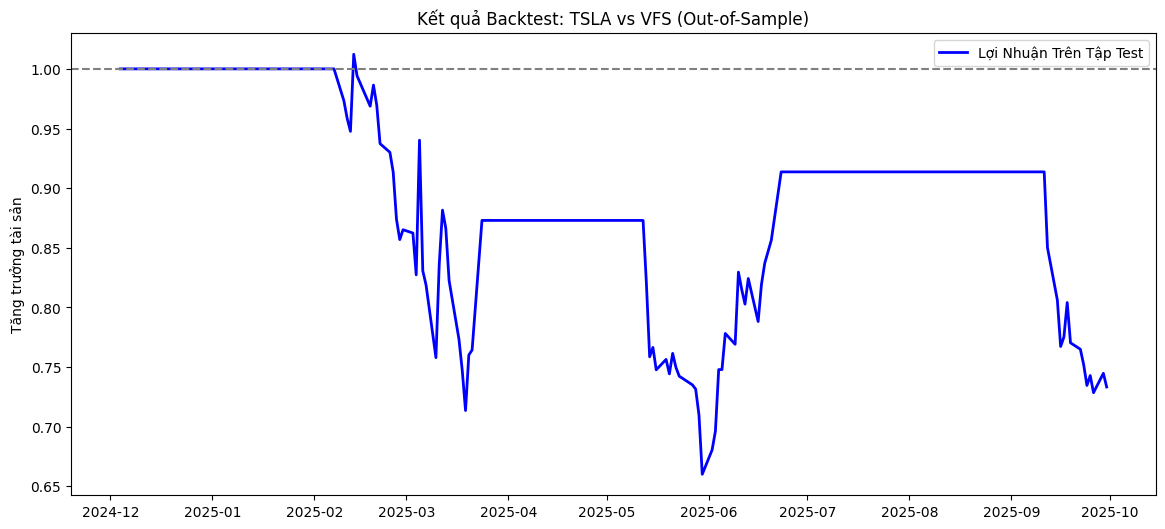

✨ Tổng lợi nhuận trên tập Test: -26.67%
Đang phân tích cặp: LCID - VFS (Hedge Ratio: 0.1174)
⚔️ Backtest cặp LCID - VFS (Chia Train/Test: 80%)...
- Train: 2021-09-07 -> 2024-12-03 (816 ngày)
- Test : 2024-12-04 -> 2025-09-30 (205 ngày)
-> Kết quả Training: Hedge Ratio: 3.7224


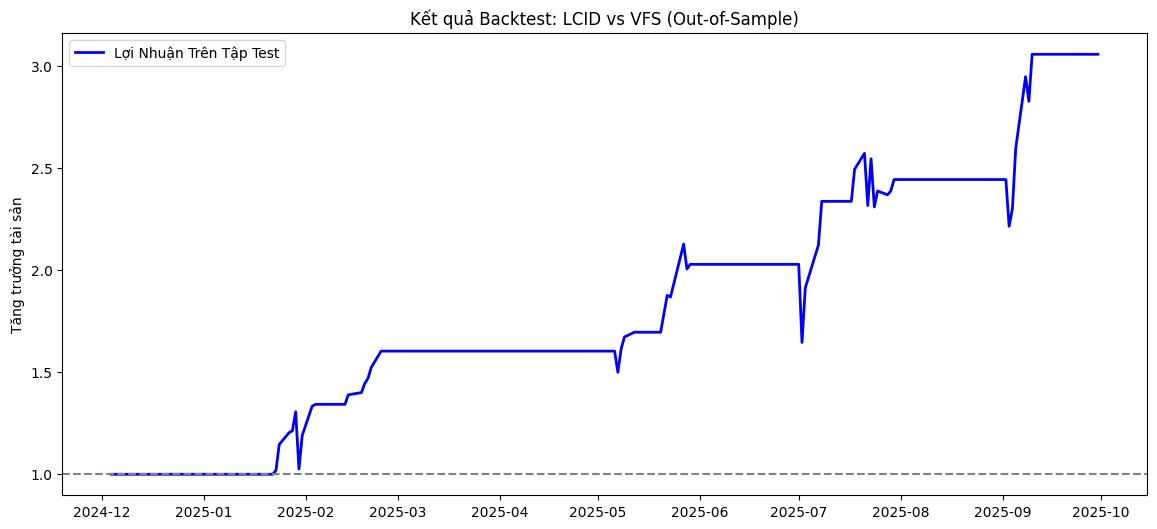

✨ Tổng lợi nhuận trên tập Test: 205.95%
Đang phân tích cặp: F - VFS (Hedge Ratio: 0.1513)
⚔️ Backtest cặp F - VFS (Chia Train/Test: 80%)...
- Train: 2021-09-07 -> 2024-12-03 (816 ngày)
- Test : 2024-12-04 -> 2025-09-30 (205 ngày)
-> Kết quả Training: Hedge Ratio: 0.0170


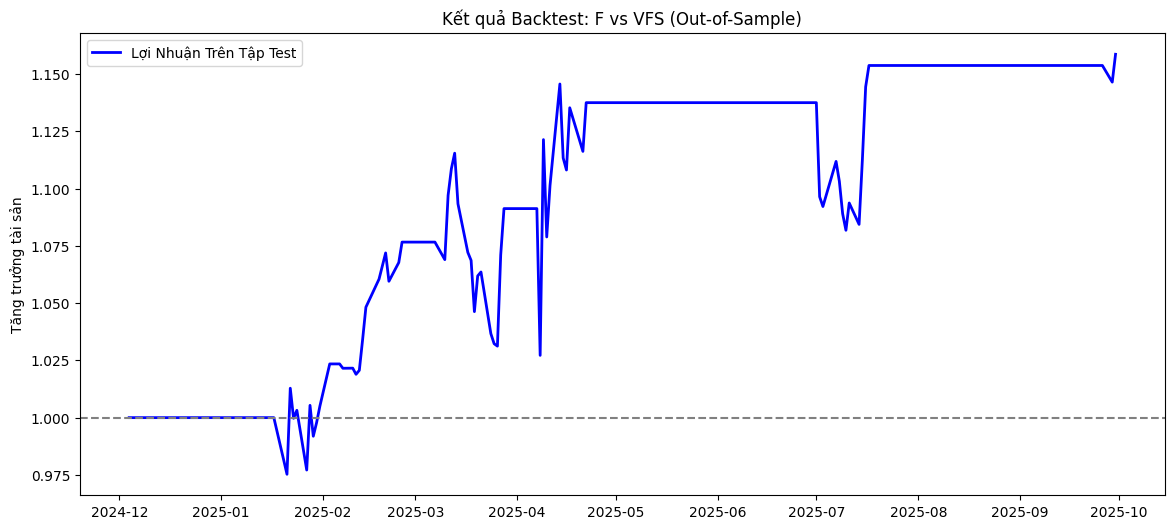

✨ Tổng lợi nhuận trên tập Test: 15.86%
Đang phân tích cặp: V - MA (Hedge Ratio: 1.3838)
⚔️ Backtest cặp V - MA (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 0.5453


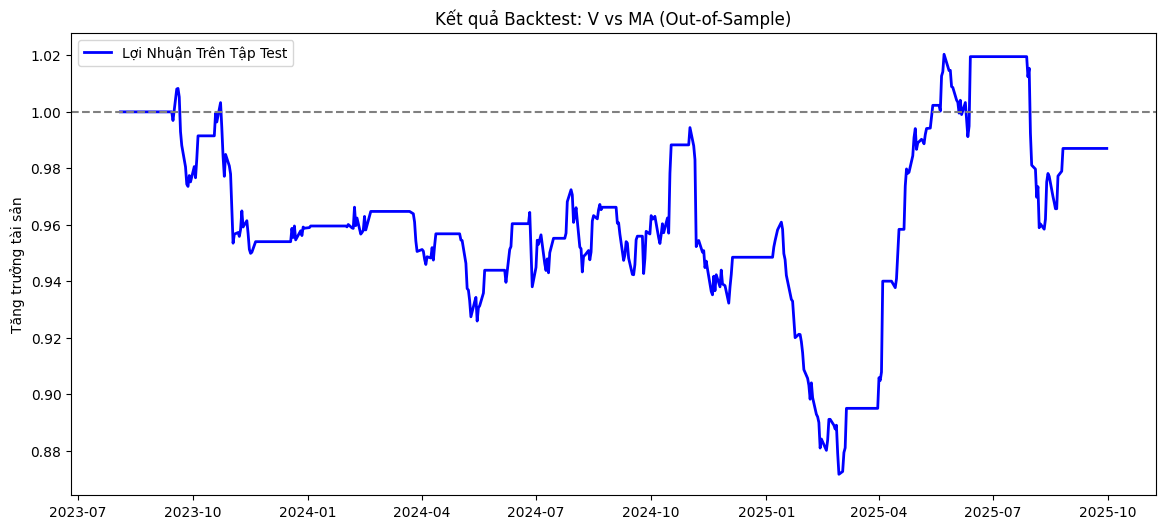

✨ Tổng lợi nhuận trên tập Test: -1.30%
Đang phân tích cặp: NKE - TGT (Hedge Ratio: 0.9764)
⚔️ Backtest cặp NKE - TGT (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 0.5804


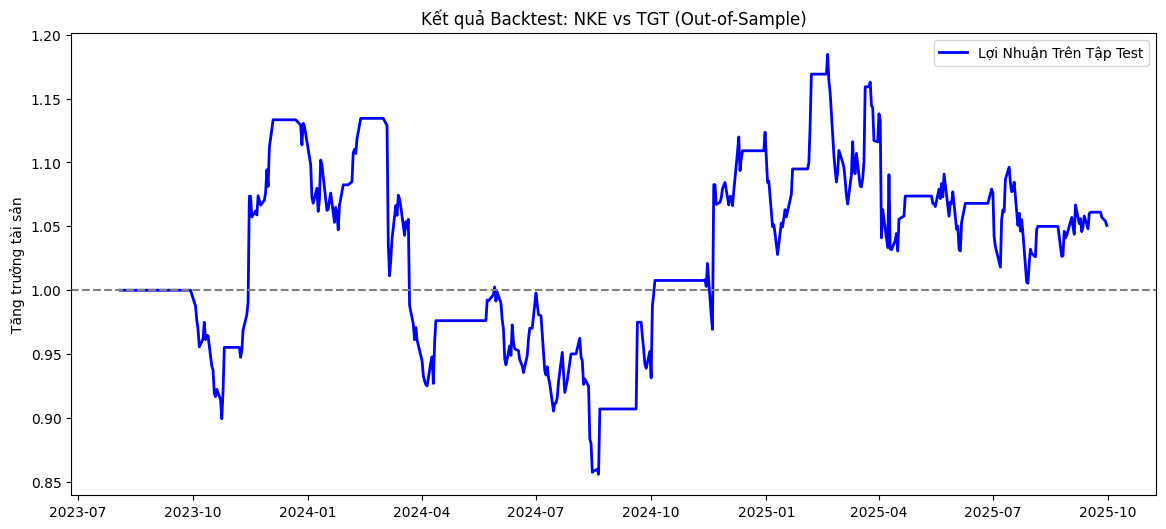

✨ Tổng lợi nhuận trên tập Test: 5.07%
Đang phân tích cặp: AAPL - AMD (Hedge Ratio: 7.4106)
⚔️ Backtest cặp AAPL - AMD (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 1.2531


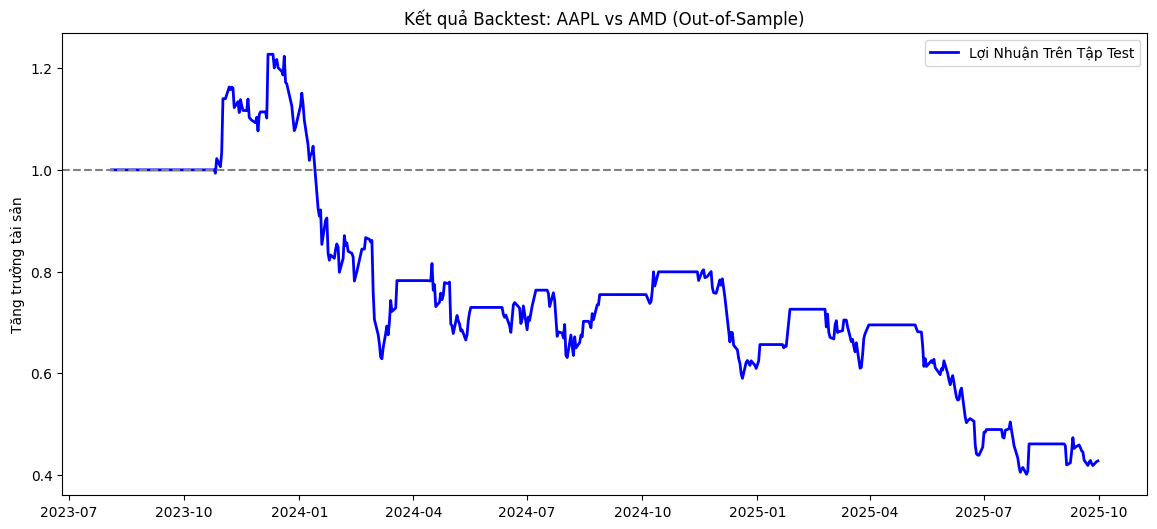

✨ Tổng lợi nhuận trên tập Test: -57.24%
Đang phân tích cặp: AAPL - MSFT (Hedge Ratio: 1.1096)
⚔️ Backtest cặp AAPL - MSFT (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 0.5564


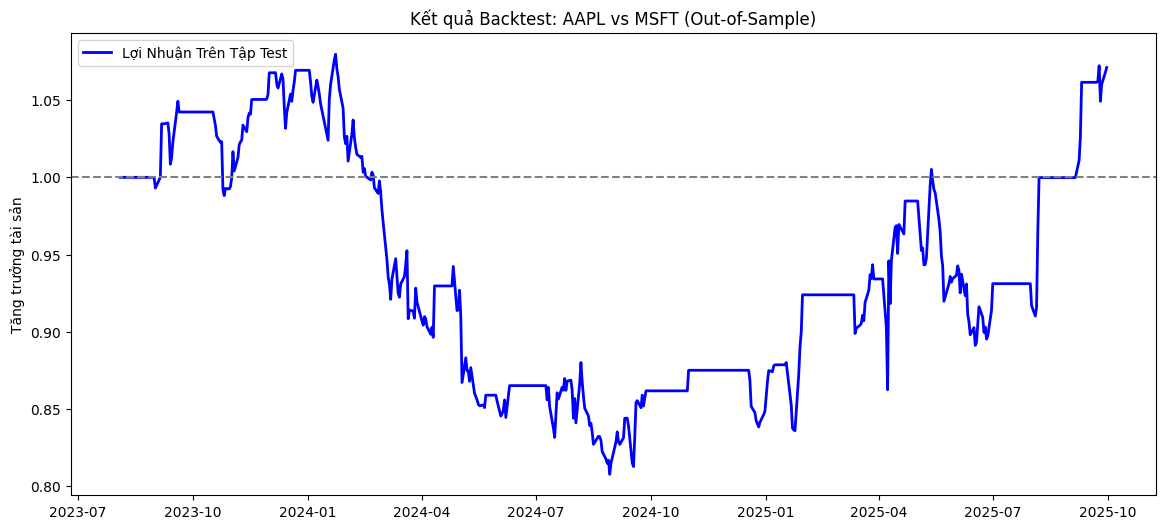

✨ Tổng lợi nhuận trên tập Test: 7.11%
Đang phân tích cặp: KO - COST (Hedge Ratio: 7.7125)
⚔️ Backtest cặp KO - COST (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 0.0637


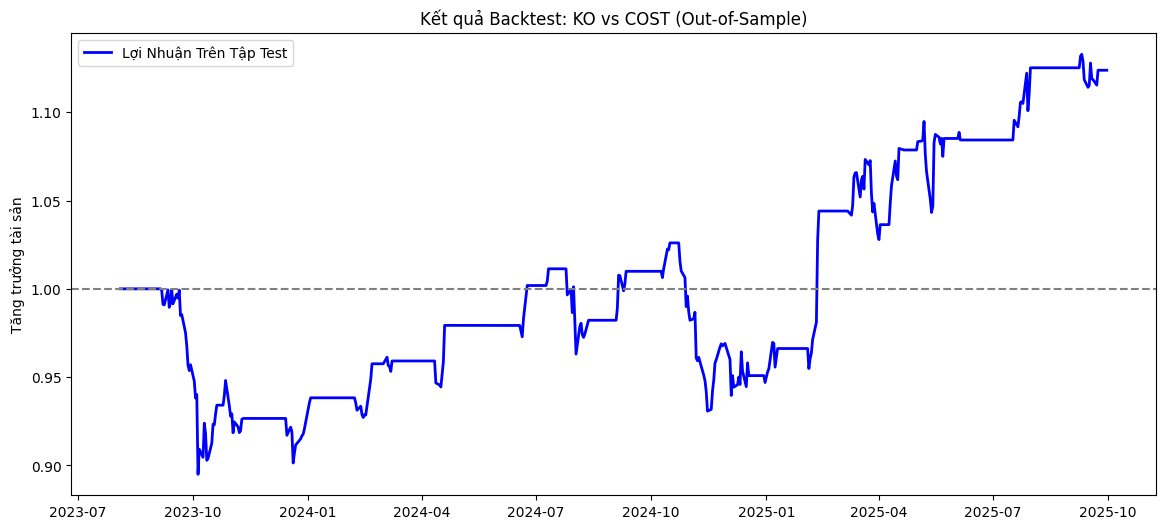

✨ Tổng lợi nhuận trên tập Test: 12.37%
Đang phân tích cặp: MCD - KO (Hedge Ratio: 0.2872)
⚔️ Backtest cặp MCD - KO (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 6.1492


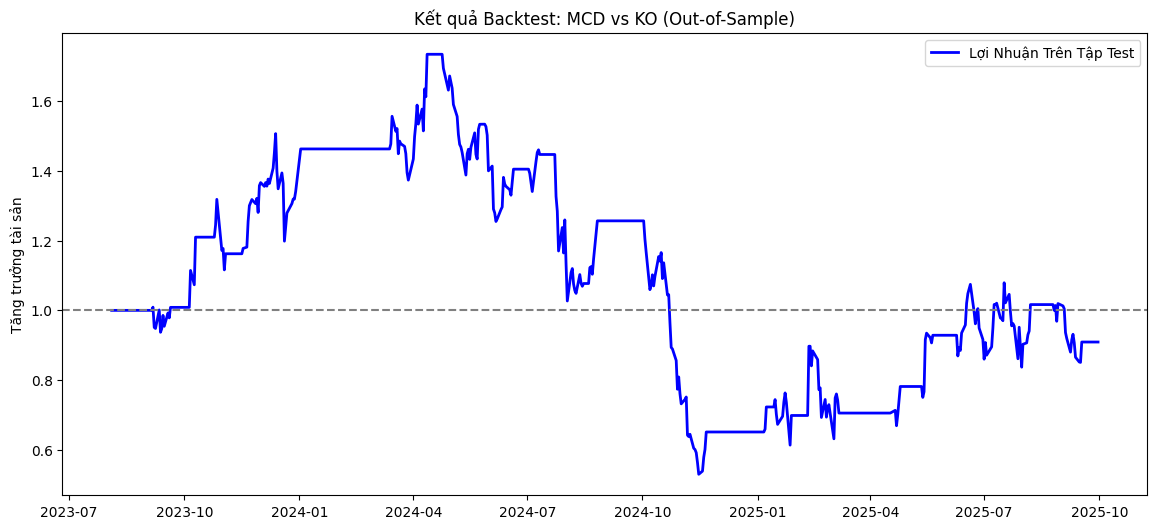

✨ Tổng lợi nhuận trên tập Test: -9.09%
Đang phân tích cặp: GOOG - MSFT (Hedge Ratio: 1.4771)
⚔️ Backtest cặp GOOG - MSFT (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 0.3598


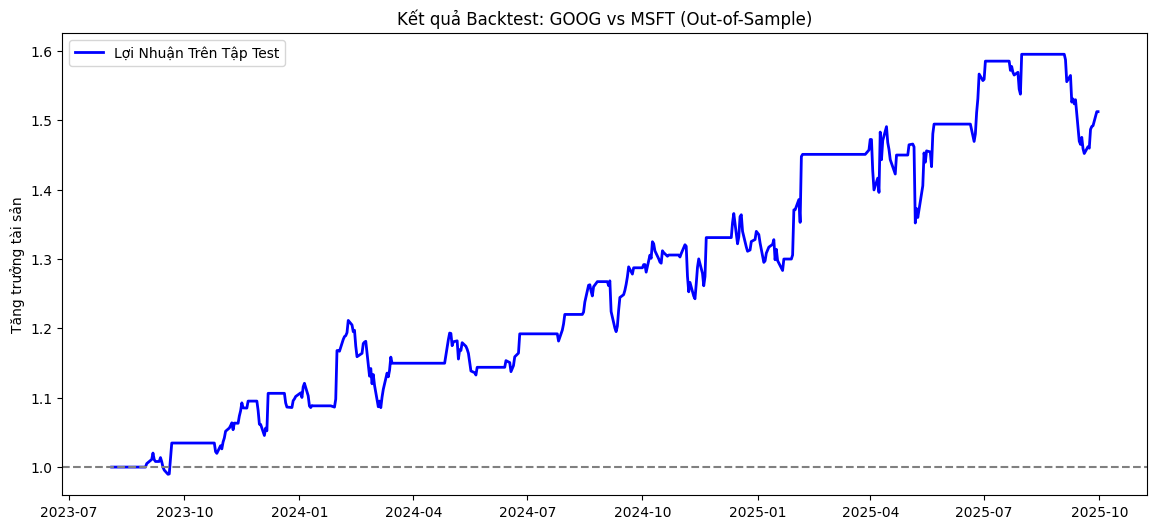

✨ Tổng lợi nhuận trên tập Test: 51.24%
Đang phân tích cặp: NOW - AMD (Hedge Ratio: 4.4356)
⚔️ Backtest cặp NOW - AMD (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 4.5575


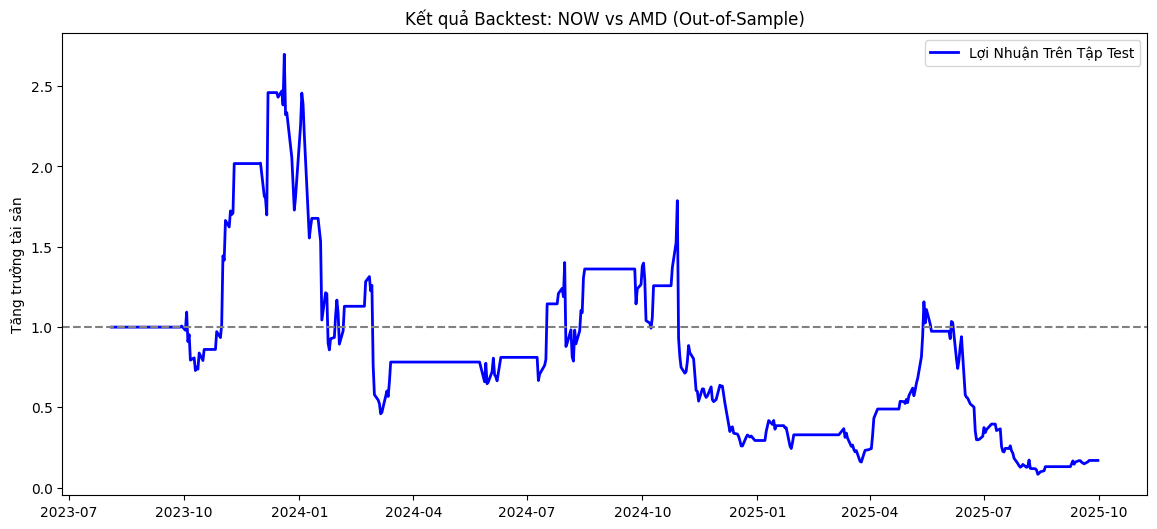

✨ Tổng lợi nhuận trên tập Test: -82.99%
Đang phân tích cặp: CRM - AMZN (Hedge Ratio: 2.9106)
⚔️ Backtest cặp CRM - AMZN (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 1.2269


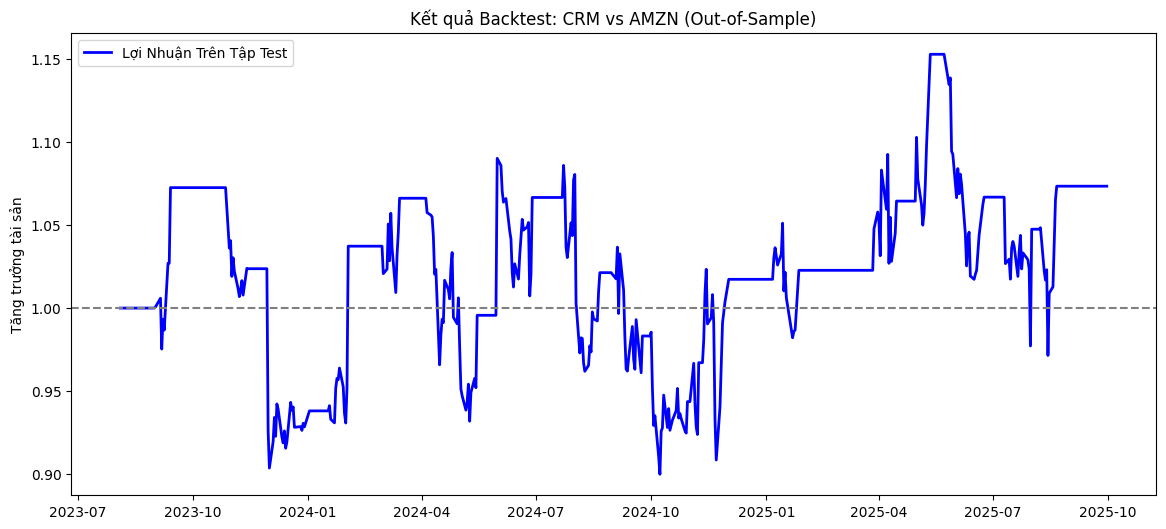

✨ Tổng lợi nhuận trên tập Test: 7.35%
Đang phân tích cặp: AMD - GOOG (Hedge Ratio: 0.0904)
⚔️ Backtest cặp AMD - GOOG (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 1.1288


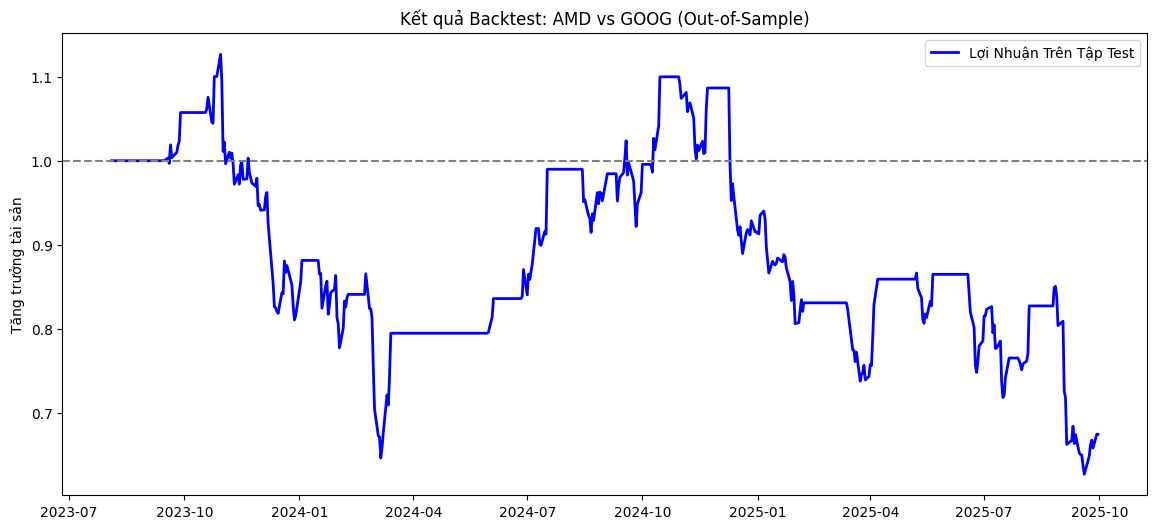

✨ Tổng lợi nhuận trên tập Test: -32.51%
Đang phân tích cặp: NOW - AMZN (Hedge Ratio: 0.8705)
⚔️ Backtest cặp NOW - AMZN (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 3.7076


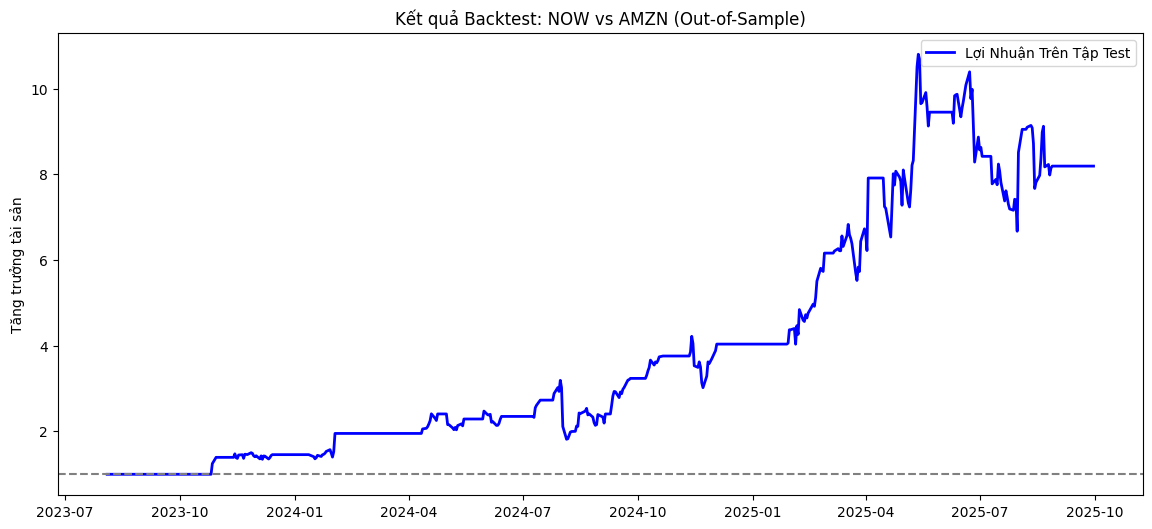

✨ Tổng lợi nhuận trên tập Test: 719.36%
Đang phân tích cặp: TSM - GOOG (Hedge Ratio: 0.7381)
⚔️ Backtest cặp TSM - GOOG (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 0.9110


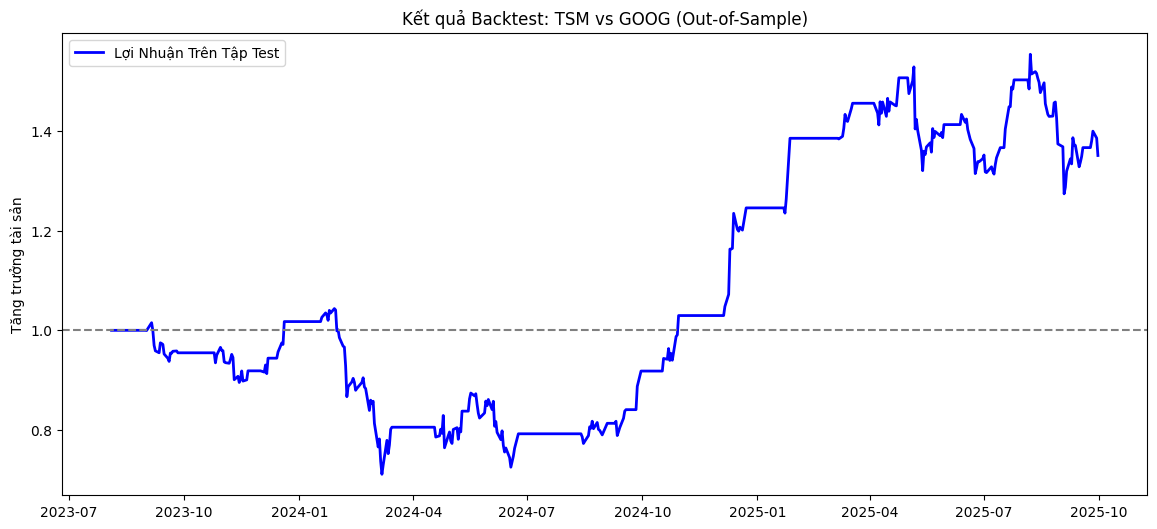

✨ Tổng lợi nhuận trên tập Test: 35.08%
Đang phân tích cặp: PG - LRLCY (Hedge Ratio: 1.6354)
⚔️ Backtest cặp PG - LRLCY (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 1.4635


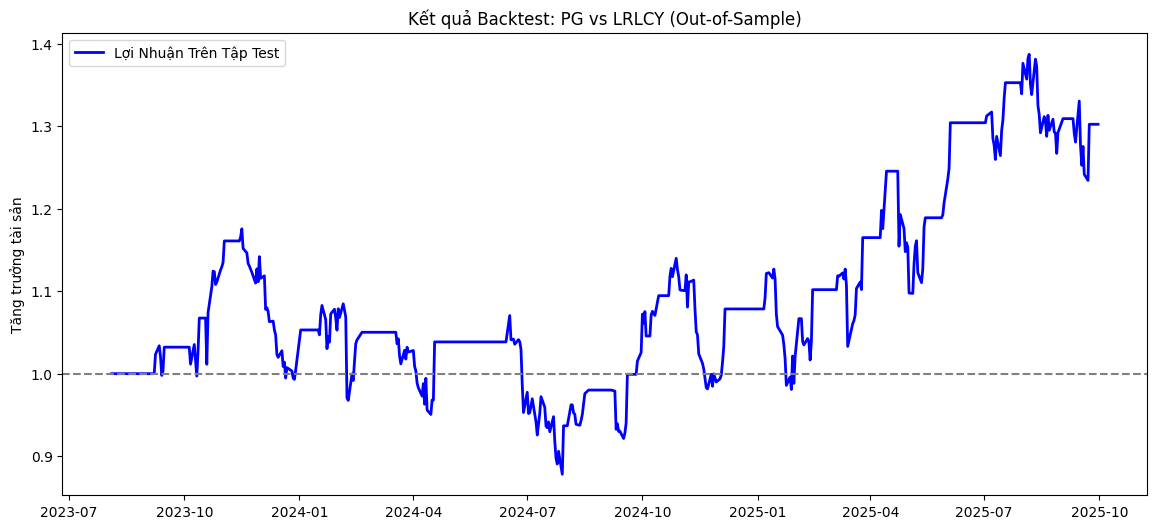

✨ Tổng lợi nhuận trên tập Test: 30.25%
Đang phân tích cặp: AMD - MSFT (Hedge Ratio: 0.1400)
⚔️ Backtest cặp AMD - MSFT (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 0.4259


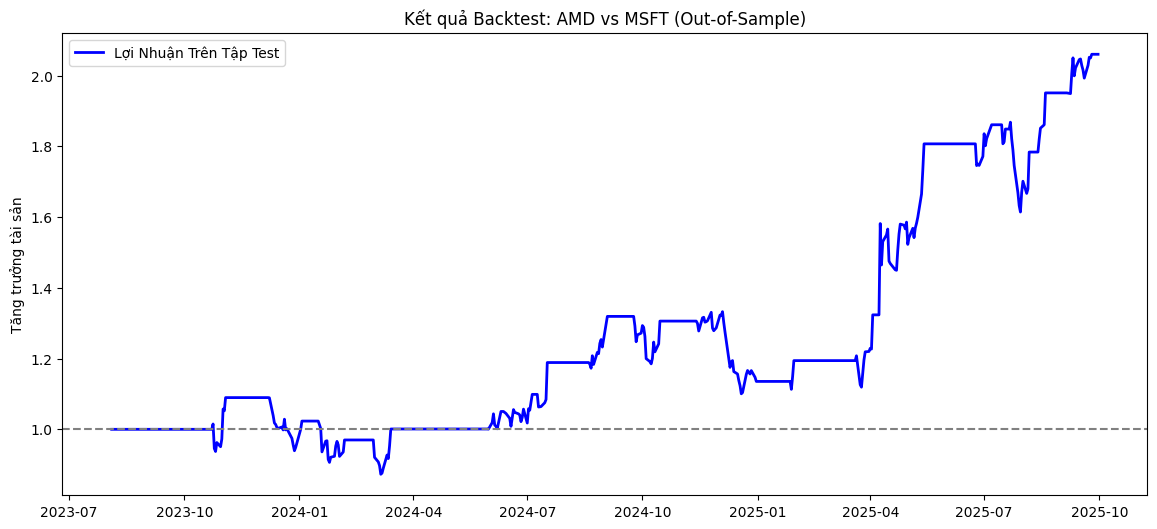

✨ Tổng lợi nhuận trên tập Test: 106.02%
Đang phân tích cặp: NOW - GOOG (Hedge Ratio: 0.4409)
⚔️ Backtest cặp NOW - GOOG (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 5.2401


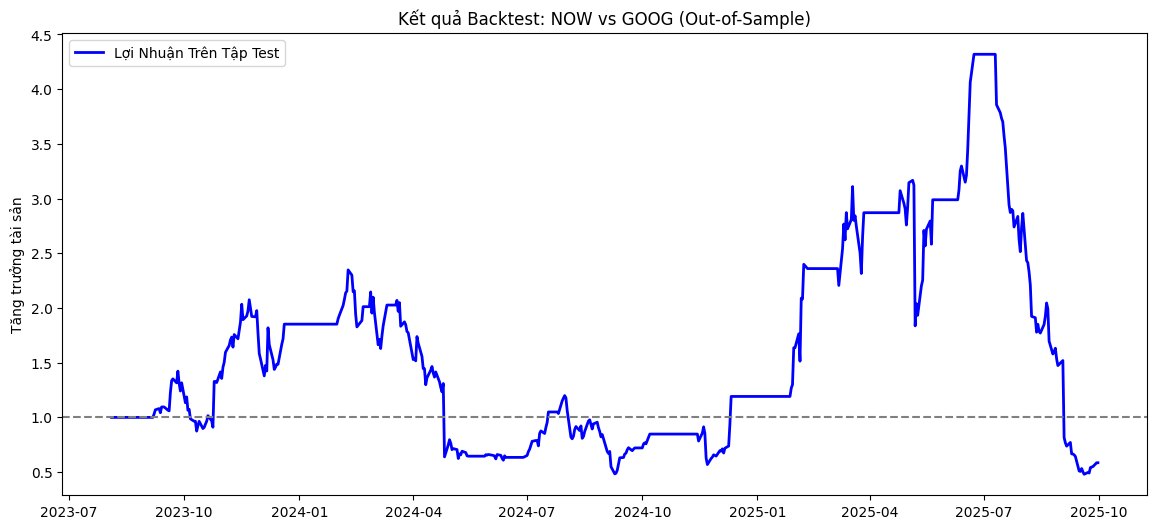

✨ Tổng lợi nhuận trên tập Test: -41.44%
Đang phân tích cặp: AAPL - NOW (Hedge Ratio: 1.5794)
⚔️ Backtest cặp AAPL - NOW (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 0.2612


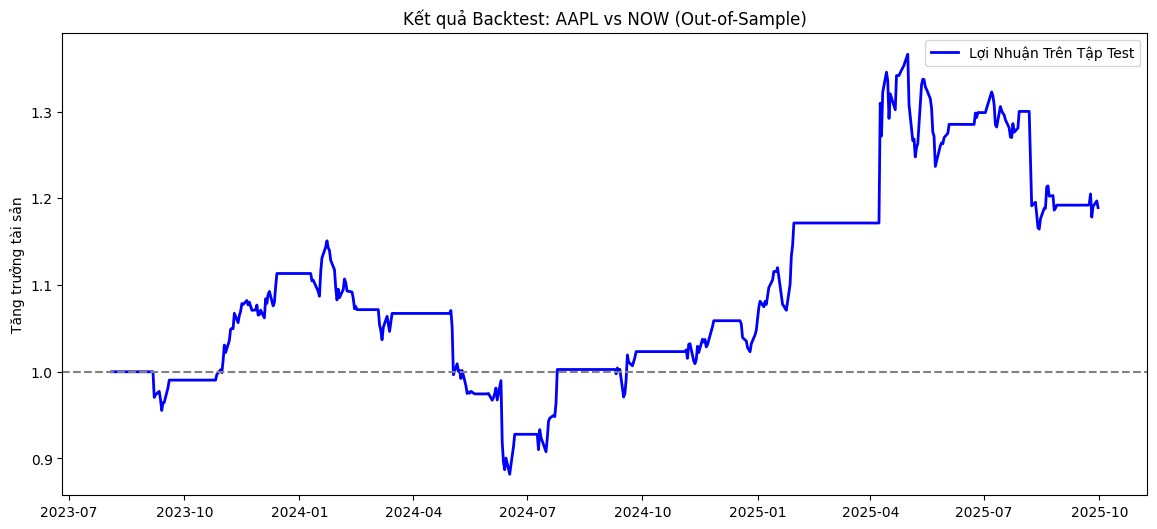

✨ Tổng lợi nhuận trên tập Test: 18.93%
Đang phân tích cặp: WMT - KO (Hedge Ratio: 0.2667)
⚔️ Backtest cặp WMT - KO (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 1.0588


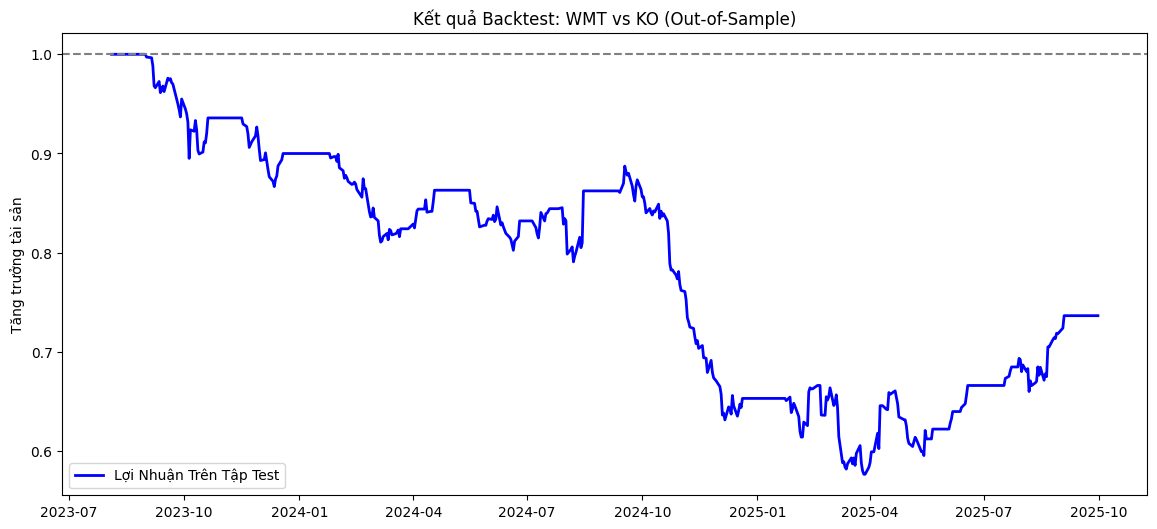

✨ Tổng lợi nhuận trên tập Test: -26.35%
Đang phân tích cặp: CVX - COP (Hedge Ratio: 1.5380)
⚔️ Backtest cặp CVX - COP (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 1.1845


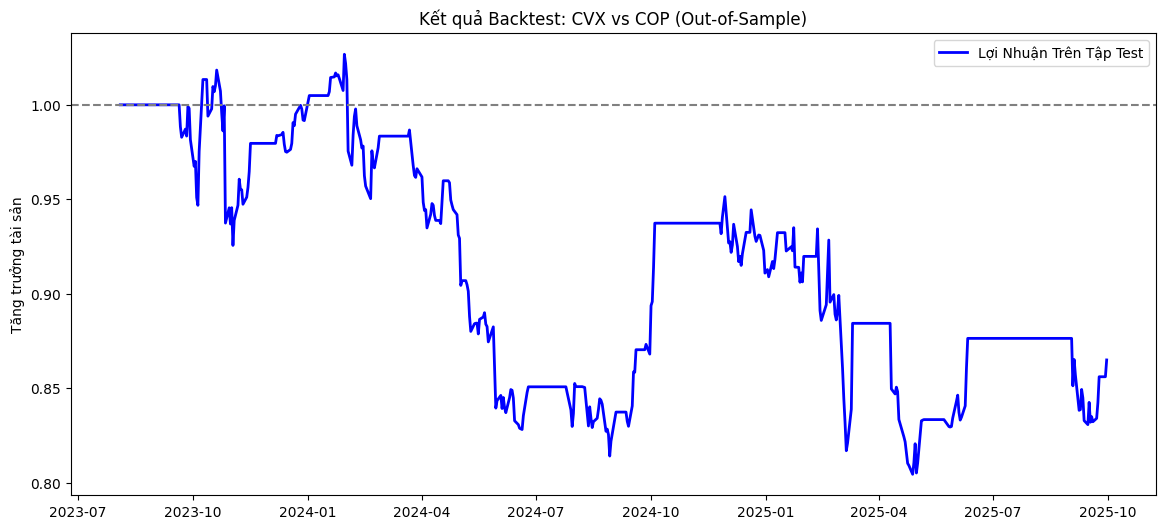

✨ Tổng lợi nhuận trên tập Test: -13.50%
Đang phân tích cặp: HD - LOW (Hedge Ratio: 1.0785)
⚔️ Backtest cặp HD - LOW (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 1.3790


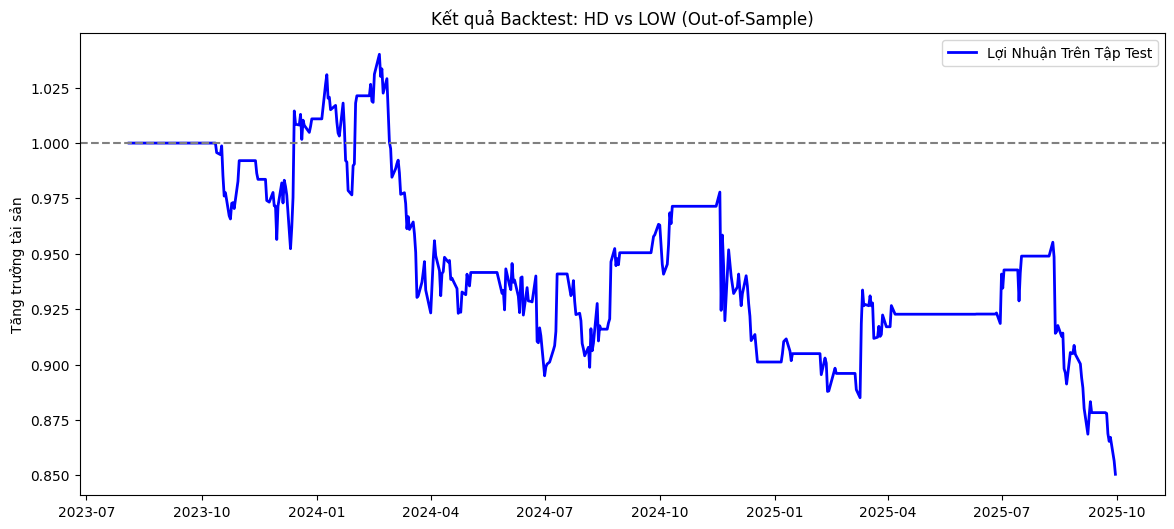

✨ Tổng lợi nhuận trên tập Test: -14.96%
Đang phân tích cặp: SBUX - TGT (Hedge Ratio: 1.1369)
⚔️ Backtest cặp SBUX - TGT (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 0.3490


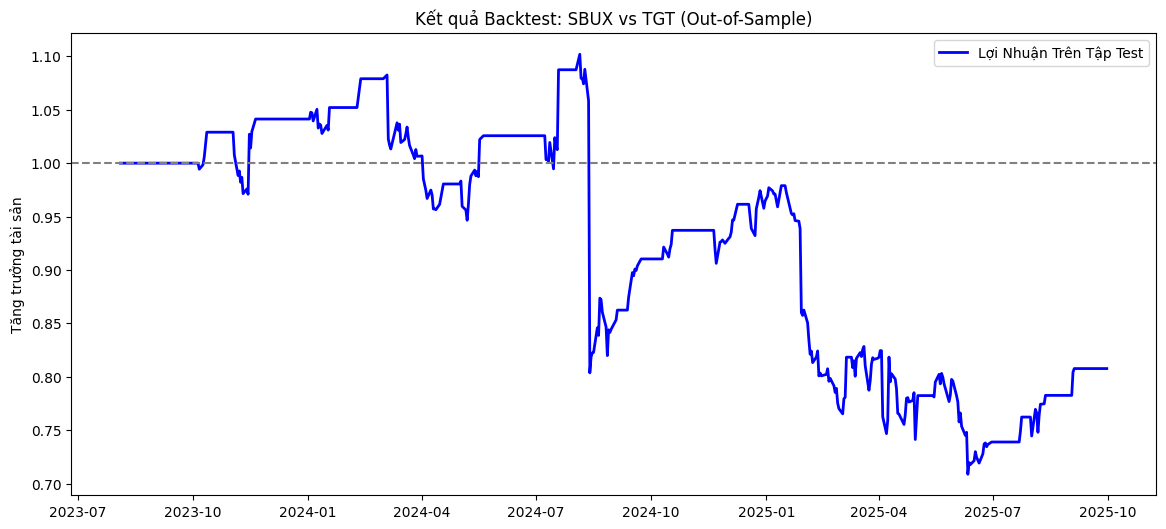

✨ Tổng lợi nhuận trên tập Test: -19.23%
Đang phân tích cặp: CMCSA - DIS (Hedge Ratio: 0.7883)
⚔️ Backtest cặp CMCSA - DIS (Chia Train/Test: 80%)...
- Train: 2015-01-02 -> 2023-08-03 (2161 ngày)
- Test : 2023-08-04 -> 2025-09-30 (541 ngày)
-> Kết quả Training: Hedge Ratio: 0.2460


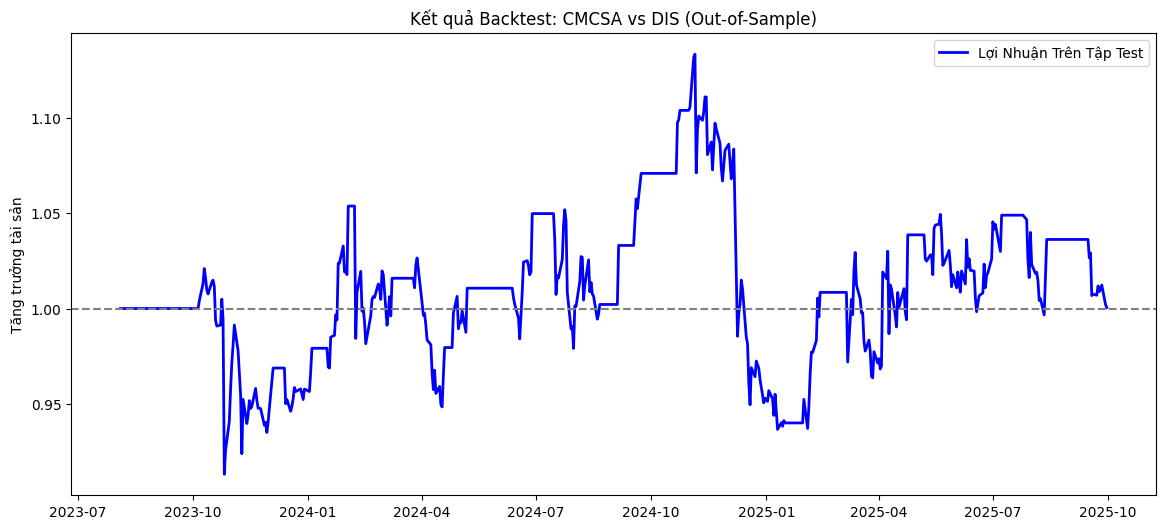

✨ Tổng lợi nhuận trên tập Test: 0.05%


In [ ]:
# --- CHẠY THỬ ---
for index, row in df_economic_pairs.iterrows():
    # 1. Lấy tên Stock 1 và Stock 2 từ dòng hiện tại
    ticker1 = row['Stock 1']
    ticker2 = row['Stock 2']

    # 2. Lấy Hedge Ratio
    hedge_ratio = row['Hedge_Ratio']

    # In ra để kiểm tra đang chạy cặp nào
    print(f"Đang phân tích cặp: {ticker1} - {ticker2} (Hedge Ratio: {hedge_ratio:.4f})")

    # 3. Gọi hàm analyze
    try:
        df_test_result = backtest_pairs_split(ticker1, ticker2, df_signal_copy, split_ratio=0.8)

    except Exception as e:
        print(f"Lỗi khi chạy cặp {ticker1}-{ticker2}: {e}")

**Tìm các mã có lợi nhuận cao sau khi đã backtest**

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

def backtest_pairs_split(ticker1, ticker2, data_dict, split_ratio=0.8, plot=True):
    # 1. CHUẨN BỊ DỮ LIỆU
    try:
        col1 = 'Adj Close' if 'Adj Close' in data_dict[ticker1] else 'Close'
        col2 = 'Adj Close' if 'Adj Close' in data_dict[ticker2] else 'Close'
        df = pd.concat([data_dict[ticker1][col1], data_dict[ticker2][col2]], axis=1, join='inner')
        df.columns = [ticker1, ticker2]
    except:
        return None, None # Trả về None nếu lỗi dữ liệu

    # 2. CHIA TRAIN / TEST
    split_index = int(len(df) * split_ratio)
    df_train = df.iloc[:split_index].copy()
    df_test = df.iloc[split_index:].copy()

    # 3. TRAINING
    X_train = sm.add_constant(df_train[ticker2])
    Y_train = df_train[ticker1]
    model = sm.OLS(Y_train, X_train).fit()
    hedge_ratio = model.params[ticker2]
    intercept = model.params['const']

    # 4. TESTING
    df_test['Spread'] = df_test[ticker1] - (hedge_ratio * df_test[ticker2] + intercept)

    window = 20
    df_test['Z_Score'] = (df_test['Spread'] - df_test['Spread'].rolling(window).mean()) / df_test['Spread'].rolling(window).std()

    # 5. LOGIC GIAO DỊCH
    position = 0
    positions = []
    entry_threshold = 2.0
    exit_threshold = 0.0

    for z in df_test['Z_Score']:
        if pd.isna(z):
            positions.append(0)
            continue
        if position == 0:
            if z < -entry_threshold: position = 1
            elif z > entry_threshold: position = -1
        elif position == 1:
            if z >= exit_threshold: position = 0
        elif position == -1:
            if z <= -exit_threshold: position = 0
        positions.append(position)

    df_test['Position'] = positions

    # 6. TÍNH LÃI
    ret1 = df_test[ticker1].pct_change()
    ret2 = df_test[ticker2].pct_change()
    df_test['Spread_Return'] = ret1 - hedge_ratio * ret2

    # Shift ngày chuẩn
    df_test['Strategy_Return'] = df_test['Position'].shift(1) * df_test['Spread_Return']
    df_test['Cumulative_PnL'] = (1 + df_test['Strategy_Return'].fillna(0)).cumprod()

    total_return = df_test['Cumulative_PnL'].iloc[-1] - 1

    # 7. VẼ HÌNH (Chỉ vẽ nếu plot=True)
    if plot:
        print(f"⚔️ Cặp {ticker1}-{ticker2}: Lãi {total_return:.2%}")
        plt.figure(figsize=(14, 6))
        plt.plot(df_test.index, df_test['Cumulative_PnL'], label='Strategy', color='blue', lw=2)
        plt.axhline(1, color='gray', linestyle='--')
        plt.title(f'Backtest: {ticker1} vs {ticker2}')
        plt.legend()
        plt.show()

    return total_return, df_test

pair_results = []

print("⏳ Đang quét hiệu quả đầu tư...")

for index, row in df_economic_pairs.iterrows():
    t1 = row['Stock 1']
    t2 = row['Stock 2']

    # Gọi hàm với chế độ plot=False để chạy ngầm cho nhanh
    ret, df_res = backtest_pairs_split(t1, t2, df_signal_copy, split_ratio=0.8, plot=False)

    if ret is not None:
        pair_results.append({
            'Pair': f"{t1} - {t2}",
            'Return': ret,
            'Data': df_res['Cumulative_PnL'] # Lưu lại đường cong vốn để vẽ sau
        })

df_results = pd.DataFrame(pair_results)
df_results = df_results.sort_values(by='Return', ascending=False) # Lãi cao nhất lên đầu

# Lấy Top 5 cặp tốt nhất (hoặc Top 10 tùy bà)
top_pairs = df_results.head(5)

print("\n🏆 CÁC CẶP LÃI CAO NHẤT TRÊN TẬP TEST:")
print(df_results[['Pair', 'Return']].to_string(formatters={'Return': '{:.2%}'.format}))

⏳ Đang quét hiệu quả đầu tư...

🏆 CÁC CẶP LÃI CAO NHẤT TRÊN TẬP TEST:
           Pair  Return
14   NOW - AMZN 719.36%
2    LCID - VFS 205.95%
17   AMD - MSFT 106.02%
10  GOOG - MSFT  51.24%
0      GM - VFS  38.24%
15   TSM - GOOG  35.08%
16   PG - LRLCY  30.25%
19   AAPL - NOW  18.93%
3       F - VFS  15.86%
8     KO - COST  12.37%
12   CRM - AMZN   7.35%
7   AAPL - MSFT   7.11%
5     NKE - TGT   5.07%
24  CMCSA - DIS   0.05%
4        V - MA  -1.30%
9      MCD - KO  -9.09%
21    CVX - COP -13.50%
22     HD - LOW -14.96%
23   SBUX - TGT -19.23%
20     WMT - KO -26.35%
1    TSLA - VFS -26.67%
13   AMD - GOOG -32.51%
18   NOW - GOOG -41.44%
6    AAPL - AMD -57.24%
11    NOW - AMD -82.99%
